# AnalyzeTCSPC — time-lapse XYZT
TCSPC-FLIM analysis for ISS Vista exports of repeated z-stacks (time-lapse, one position or an Olympus MATL tile grid;
`..._Decay<nbin>_<nx>x<ny>_Z<timepoints·tiles·z>_...tif`).
**Step 0** converts the raw float32 file to uint8 stacks per timepoint (and tile), measures the drift of every
timepoint, and writes on one drift-corrected canvas the time-summed TCSPC volume and one TCSPC volume per timepoint.
Steps 1–16 are the `AnalyzeTCSPC.ipynb` pipeline run on the time sum (segmentation, per-cell fits); **Step 17**
measures every cell at every timepoint with the same masks. Single acquisitions: `AnalyzeTCSPC_XYTZTile.ipynb`.

Run cells **in order**. Edit the **Step 0a** cell for each experiment.

In [16]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'   # prevent OpenMP conflict between MKL and torch on Windows

import torch   # must be imported before numpy/scipy to avoid OpenMP runtime clash

import sys
import csv
import json
import glob
import re
import warnings
import importlib
import tkinter as tk
from tkinter import filedialog
from collections import defaultdict

from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import tifffile
import pandas as pd
from scipy.ndimage import median_filter, gaussian_filter
from skimage.restoration import (denoise_bilateral,
                                  denoise_nl_means as _nlm_fn,
                                  rolling_ball as _rolling_ball_fn,
                                  estimate_sigma as _esig_fn)
from imageio import imwrite
from cellpose import models as _cp_models

sys.path.insert(0, 'X:/FLIM_2026')
import FastFLIM_mod_AT0 as _ffm_module
from FastFLIM_mod_AT0 import FastFLIM_mod_AT0
from flim_helpers import uplowthresh, Fit_decay, Calc_Phasor_Mat, phasor_ref_correction, read_fbs_metadata
import multiday as md

print(f'torch {torch.__version__}  CUDA {torch.version.cuda}  GPU available: {torch.cuda.is_available()}')

torch 2.5.1+cu121  CUDA 12.1  GPU available: True


## Helper functions
`uplowthresh` finds upper/lower display thresholds from the pixel histogram.
`Fit_decay` fits a multi-exponential model to the spatially-averaged decay.
`Calc_Phasor_Mat` computes phasor components and the density matrix.

## Step 0: Time-lapse acquisition → uint8 stacks per timepoint → drift correction → stitched TCSPC
Vista blocks are ordered time > tile > z. One position: `tile_grid = (1, 1)` (tile registration is skipped).
- **0a** parameters & metadata. Bins, tile size and number of z-blocks come from the Vista file name (`_Decay128`,
  `_512x512`, `_Z210`). Read automatically when present, otherwise the defaults in the cell are used (printed):
  - tile grid (max `yIndex`/`xIndex` + 1), overlap and acquisition order ← Olympus `matl.omp2info`
    (searched below the raw file's folder);
  - voxel size (xy pixel, z step) ← the Olympus `.oir` tiles;
  - laser period `Tcycle` ← `TacTimeRange` in the ISS `<name>.fbs.xml` next to the raw file, checked against the
    laser frequency.
- **0b** float32 → uint8: one ImageJ hyperstack per tile (`ZCYX`, decay bins as channels) in `analysis/tiles_uint8/`, in the
  file's block order. Vista writes classic TIFFs past 4 GB: pages after ~4 GB have no IFD, and their IFDs are written
  over plane data in the first 4 GB. Those pixels are located exactly and zeroed (reported as *corrupted bins*).
  **Dropped planes:** Vista can miss planes the microscope acquired; every later block then sits in a slot too early
  and the last blocks of the file stay empty. With Olympus tiles (same scan, complete), every block is matched to the
  Olympus frame it shows and moved to its true tile / z (`<base>_block_map.json`); planes never recorded stay empty
  (no photons, coverage 0) and a block straddling a gap is discarded. A warning lists the missing planes. Without
  Olympus tiles, empty blocks only trigger a warning (the stitch is then unreliable).
- **0c** registration: masked normalised cross-correlation on neighbour overlaps → integer (dz, dy, dx) per tile,
  global least squares. The tile order is the acquisition order from `matl.omp2info`; without it,
  `tile_layout='auto'` scores raster/snake × start corner (and the transposed grid) and `tile_layout_fallback` is
  used when nothing matches or it ties with the best. `max_dz` bounds the z offset between neighbours: with a tilted
  objective, neighbouring tiles are several planes apart (2026-11-06: 3–10 planes); a pair at the bound gives a
  warning. `tile_reg_source='auto'` registers on the Olympus PMT channel when its tiles exist (complete, no diffuse
  background; same scan, so the positions apply to both), otherwise on the time-projected FLIM intensity. Positions are recomputed when a registration setting or
  the block assignment of 0b changes.
- **0d** stitching: TCSPC overlaps are **summed** (raw counts, more photons per decay) → `analysis/stitched/` (= `data_folder`
  for Steps 1–16). Segmentation intensity is per-tile normalised and feather-blended →
  `analysis/intensity_coverage/<base>_stitched_intensity.tif`
  (used by Step 2 instead of summing `data_paths`, so overlaps are not double-counted).
- **0e** Olympus PMT channel (e.g. mCherry, red light sent to the Olympus PMT by the beamsplitter): the `.oir` tiles
  are read, their pixel offset to the TCSPC tiles is measured (same scan, two detectors) and corrected, and they are
  stitched with the **same tile positions** as 0c → `intensity_coverage/<base>_stitched_<CH>.tif`, the default segmentation input of Step 2.
- **Time series** (`n_timepoints` > 1: repeated z-stacks; Vista blocks are ordered time > tile > z). `n_timepoints`
  comes from the Olympus `.oir` when present (its time axis, else Vista blocks / (tiles × planes)), otherwise from 0a.
  Tiles are registered on timepoint `time_ref`; the drift of every timepoint vs `time_ref` is measured as an integer
  (dz, dy, dx) (`time_drift`; integer, so photon counts are never resampled; `time_max_dz` bounds z). 0d puts all
  timepoints on one canvas: their **sum** → `stitched/` (Steps 1–16; Step 2 segments the time-summed intensity) and
  **each timepoint** → `stitched_timepoints/T<tt>/` (Step 17: per-cell FLIM per timepoint with the same masks). The Olympus block
  check and 0e are skipped for time series until a time-lapse `.oir` has been seen.

Outputs are reused when present; set `rerun_convert / rerun_register / rerun_fuse / rerun_oir` to redo a step
(re-registering re-stitches automatically). Tile offsets: `<base>_tile_positions.json`.

**Output layout:** everything goes below `analysis/` in the raw file's folder (the raw folder keeps only the raw data):
```
analysis/
  <base>_tile_positions.json, <base>_block_map.json
  tiles_uint8/            uint8 tile stacks (per timepoint) + conversion report        (0b)
  intensity_coverage/     <base>[_T<tt>]_stitched_intensity.tif, <base>[_T<tt>]_coverage.tif,
                          <base>_stitched_<CH>.tif (Olympus)                           (0d, 0e)
  stitched/               time-sum TCSPC planes = data_folder of Steps 1–16           (0d)
    <YYYYMMDD_HHMM>_FLIM_Analysis/   results of Steps 1–17
  stitched_timepoints/
    T00/, T01/, ...       registered (drift-corrected) TCSPC planes per timepoint      (0d, Step 17)
```
Outputs of the old flat layout (loose next to the raw file) are moved here by Step 0a: a rename on the same drive,
so the modification times and every cache stay valid; nothing is overwritten.


In [17]:
# ── Step 0a: time-lapse acquisition parameters ────────────────────────────────
import vista_tiles as vt
import olympus_oir as oo
importlib.reload(vt)
importlib.reload(oo)

def _pick_raw():
    root = tk.Tk(); root.withdraw(); root.attributes('-topmost', True)
    p = filedialog.askopenfilename(title='Select ISS Vista XYTZ TIFF',
                                   filetypes=[('TIFF files', '*.tif *.tiff'), ('All files', '*.*')])
    root.destroy()
    return p or None

# ── raw file — swap comments to switch between hardcoded and interactive ──────
raw_path = r"D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\Slice3_DG_CA3_baseline1_Decay128_512x512_Z72_Ch1_T1_P1_S1.tif"
# raw_path = _pick_raw()
if not raw_path:
    raise RuntimeError('No raw file selected.')

# ── defaults: used only where the metadata read below are missing ─────────────
tile_grid    = (1, 1)    # (rows, cols)                <- matl.omp2info; (1, 1) = single position
tile_overlap = 0.20      # nominal fractional overlap  <- matl.omp2info (the true step is measured)
xy_pixel_um  = 0.99      # XY pixel size in µm          <- Olympus .oir
z_step_um    = 8.0       # Z step in µm                 <- Olympus .oir
Tcycle       = 12.5      # laser period in ns (80 MHz)  <- TacTimeRange in the ISS .fbs.xml
n_timepoints = 8         # timepoints (repeated stacks)  <- Olympus .oir

# ── tile registration ─────────────────────────────────────────────────────────
tile_layout          = 'auto'       # 'auto': acquisition order from matl.omp2info, else detected from the
                                    #  overlaps (also tests the transposed grid); or one of vt.LAYOUTS
tile_layout_fallback = 'snake_tl'   # detection only: used when nothing matches or it ties with the best
tile_shape_px        = None         # (ny, nx) per tile; None = from file name '_<nx>x<ny>_'
max_dz               = 12           # max z offset between neighbouring tiles (planes); a tilted objective
                                    #  puts neighbours several planes apart (2026-11-06: 3-10 planes)
tile_reg_source      = 'auto'       # 'auto' = Olympus PMT channel if its tiles exist, else 'flim'; or 'flim' / 'olympus'

# ── time series (n_timepoints > 1): Vista blocks ordered time > tile > z ───────
time_ref    = 0          # reference timepoint: tile registration and drift correction (-1 = last)
time_drift  = True       # shift every timepoint onto time_ref by an integer (dz, dy, dx): counts are never resampled
time_max_dz = 4          # max z drift of a timepoint vs time_ref (planes)

# ── Olympus multi-area folder: matl.omp2info + one .oir per tile ──────────────
olympus_dir = 'auto'     # 'auto' = search below the raw file's folder; or a path; None = ignore
oir_channel = 'auto'     # Step 0e channel: 'auto' = red emission filter (else brightest), or a name, e.g. 'CH1'

rerun_convert  = False
rerun_register = False
rerun_fuse     = False

# ── derived ───────────────────────────────────────────────────────────────────
vista_info = vt.parse_vista_name(raw_path)
if tile_shape_px is not None and tuple(tile_shape_px) != (vista_info['ny'], vista_info['nx']):
    raise ValueError(f'tile_shape_px {tile_shape_px} != file name {vista_info["ny"]}x{vista_info["nx"]}')
raw_dir   = os.path.dirname(raw_path)
print(f'Raw file: {raw_path}  ({os.path.getsize(raw_path) / 1e9:.1f} GB)')

# ── outputs: everything Steps 0-17 write goes below <raw folder>/analysis/ ─────
out_root  = os.path.join(raw_dir, 'analysis')
tiles_dir = os.path.join(out_root, 'tiles_uint8')            # uint8 tile stacks per timepoint (0b)
int_dir   = os.path.join(out_root, 'intensity_coverage')     # stitched intensity + coverage volumes (0d, 0e)
tp_dir    = os.path.join(out_root, 'stitched_timepoints')    # registered TCSPC planes per timepoint: T00/, T01/, ... (0d)
pos_json  = os.path.join(out_root, f'{vista_info["base"]}_tile_positions.json')
vt.move_legacy_outputs(raw_dir, vista_info['base'], out_root, int_dir, tp_dir)   # old flat layout -> analysis/
os.makedirs(int_dir, exist_ok=True)
print(f'Outputs   -> {out_root}')

# tile layout <- Olympus multi-area protocol
matl_info = None
if olympus_dir == 'auto':
    olympus_dir = oo.find_matl_dir(raw_dir)
if olympus_dir:
    matl_info = oo.read_matl_info(olympus_dir)
    tile_grid = matl_info['grid']
    tile_overlap = matl_info['overlap'] if matl_info['overlap'] is not None else tile_overlap
    _rc = ' '.join(f'({r},{c})' for r, c in matl_info['grid_rc'])
    print(f'Tile config  <- matl.omp2info  ({os.path.relpath(olympus_dir, raw_dir)})')
    print(f'  grid {tile_grid[0]} rows x {tile_grid[1]} cols  |  overlap {tile_overlap:.0%}  |  '
          f'acquisition order {matl_info["layout"] or "not a standard layout"}  (row,col): {_rc}')
else:
    print(f'Tile config  <- DEFAULTS (no matl.omp2info below the raw folder)')
    print(f'  grid {tile_grid[0]} rows x {tile_grid[1]} cols  |  overlap {tile_overlap:.0%}  |  '
          f'layout {"detected from the overlaps" if tile_layout == "auto" else tile_layout}')
_reg_layout = (matl_info['layout'] if tile_layout == 'auto' and matl_info and matl_info['layout']
               else tile_layout)
n_tiles  = tile_grid[0] * tile_grid[1]

# Olympus .oir metadata: voxel size, planes per tile, timepoints (the ISS .fbs.xml ImageRegion is a placeholder)
oir_meta, oir_ch = None, None
_oir0 = next((f for f in matl_info['files'] if f), None) if matl_info else None
if _oir0:
    oir_meta = oo.oir_metadata(_oir0)
    oir_ch   = oo.pick_channel(oir_meta, oir_channel, path=_oir0)

# timepoints <- Olympus .oir (its time axis, else Vista blocks / (tiles x planes)); the manual value without it
_nb    = vista_info['n_blocks']
_t_src = 'MANUAL (no Olympus .oir)'
if oir_meta:
    _t_oir = oir_meta['n_t'] if oir_meta['n_t'] > 1 else _nb // (n_tiles * oir_meta['n_z'])
    if _t_oir >= 1 and _t_oir * n_tiles * oir_meta['n_z'] == _nb:
        if _t_oir != n_timepoints:
            print(f'n_timepoints {n_timepoints} -> {_t_oir} (Olympus .oir)')
        n_timepoints = _t_oir
        _t_src = ('Olympus .oir time axis' if oir_meta['n_t'] > 1 else
                  f'Olympus .oir ({_nb} Vista blocks / {n_tiles} tiles x {oir_meta["n_z"]} planes)')
    else:
        _t_src = (f'MANUAL (Olympus .oir: {oir_meta["n_t"]} timepoint(s) x {n_tiles} tiles x {oir_meta["n_z"]} planes '
                  f'!= {_nb} Vista blocks)')
if _nb % (n_tiles * n_timepoints):
    raise ValueError(f'_Z{_nb} is not a multiple of {n_timepoints} timepoint(s) x {n_tiles} tiles ({tile_grid[0]}x'
                     f'{tile_grid[1]} grid{"" if matl_info else ", default"}): set tile_grid = (1, 1) for a single '
                     f'position, n_timepoints for a time series')
n_z_tile = _nb // (n_tiles * n_timepoints)
time_ref = time_ref % n_timepoints
print(f'  {vista_info["nbin"]} bins  |  tile {vista_info["ny"]}x{vista_info["nx"]} px  |  {_nb} z-blocks = '
      + (f'{n_timepoints} timepoints x ' if n_timepoints > 1 else '') + f'{n_tiles} tiles x {n_z_tile} z')
print(f'Timepoints   <- {_t_src}:  {n_timepoints}'
      + (f'  (reference t{time_ref:02d}, drift correction {"on" if time_drift else "off"})' if n_timepoints > 1 else ''))
if n_timepoints == 1:
    warnings.warn('n_timepoints = 1: not a time series (Step 17 is skipped). Single acquisitions: '
                  'AnalyzeTCSPC_XYTZTile.ipynb', RuntimeWarning)

if oir_meta and oir_meta['pixel_um'] and oir_meta['z_step_um']:
    xy_pixel_um, z_step_um = float(oir_meta['pixel_um'][1]), float(oir_meta['z_step_um'])
    print(f'Voxel size   <- Olympus .oir:  xy {xy_pixel_um:.4f} µm  |  z {z_step_um:g} µm  '
          f'({oir_meta["n_z"]} planes per tile)')
    if (oir_meta['n_z'], oir_meta['ny'], oir_meta['nx']) != (n_z_tile, vista_info['ny'], vista_info['nx']):
        print(f'  WARNING: Olympus tiles are {oir_meta["n_z"]}x{oir_meta["ny"]}x{oir_meta["nx"]} (z,y,x), '
              f'Vista tiles {n_z_tile}x{vista_info["ny"]}x{vista_info["nx"]} — check the pairing (Step 0e is skipped)')
else:
    print(f'Voxel size   <- DEFAULTS (no Olympus .oir):  xy {xy_pixel_um} µm  |  z {z_step_um} µm')
if oir_ch:
    _others = ', '.join(f'{c["name"]} ({c["filter"]})' for c in oir_meta['channels'] if c['id'] != oir_ch['id'])
    print(f'Olympus channel for Step 0e: {oir_ch["name"]} ({oir_ch["filter"]}, {oir_ch["voltage"]:g} V)'
          + (f'  |  not used: {_others}' if _others else ''))

# laser period <- TacTimeRange in the ISS .fbs.xml
fbs_xml  = vt.find_fbs_xml(raw_path)
fbs_meta = read_fbs_metadata(fbs_xml) if fbs_xml else None
if fbs_meta and fbs_meta['Tcycle']:
    Tcycle = float(fbs_meta['Tcycle'])
    print(f'Laser period <- TacTimeRange in {os.path.basename(fbs_xml)}:  Tcycle {Tcycle:.4f} ns  '
          f'(dt {Tcycle / vista_info["nbin"]:.4f} ns/bin)')
    if fbs_meta['freq_mhz'] and abs(1000.0 / fbs_meta['freq_mhz'] - Tcycle) > 0.01 * Tcycle:
        warnings.warn(f'TacTimeRange {Tcycle:.4f} ns != laser period {1000.0 / fbs_meta["freq_mhz"]:.4f} ns '
                      f'(MacroTimeClockFrequency): check the Vista acquisition settings', RuntimeWarning)
else:
    print(f'Laser period <- DEFAULT Tcycle {Tcycle} ns  '
          f'({"no TacTimeRange in " + os.path.basename(fbs_xml) if fbs_xml else "no .fbs.xml next to the raw file"})')


Raw file: D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\Slice3_DG_CA3_baseline1_Decay128_512x512_Z72_Ch1_T1_P1_S1.tif  (9.7 GB)
Outputs   -> D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\analysis
Tile config  <- matl.omp2info  (Olympus)
  grid 1 rows x 1 cols  |  overlap 20%  |  acquisition order snake_tl  (row,col): (0,0)
n_timepoints 8 -> 9 (Olympus .oir)
  128 bins  |  tile 512x512 px  |  72 z-blocks = 9 timepoints x 1 tiles x 8 z
Timepoints   <- Olympus .oir time axis:  9  (reference t00, drift correction on)
Voxel size   <- Olympus .oir:  xy 0.9944 µm  |  z 8 µm  (8 planes per tile)
Olympus channel for Step 0e: CH1 (BA575-645, 650 V)  |  not used: CH2 (BA495-540)
Laser period <- TacTimeRange in Slice3_DG_CA3_baseline1.fbs.xml:  Tcycle 12.4976 ns  (dt 0.0976 ns/bin)


Reusing converted tiles in D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\analysis\tiles_uint8
Corrupted bins zeroed: 0.185%  |  residual junk: 2  |  clipped >255: 0  |  max count/bin/px: 25
Olympus block check skipped: time series (reading a time-lapse .oir is not implemented yet)


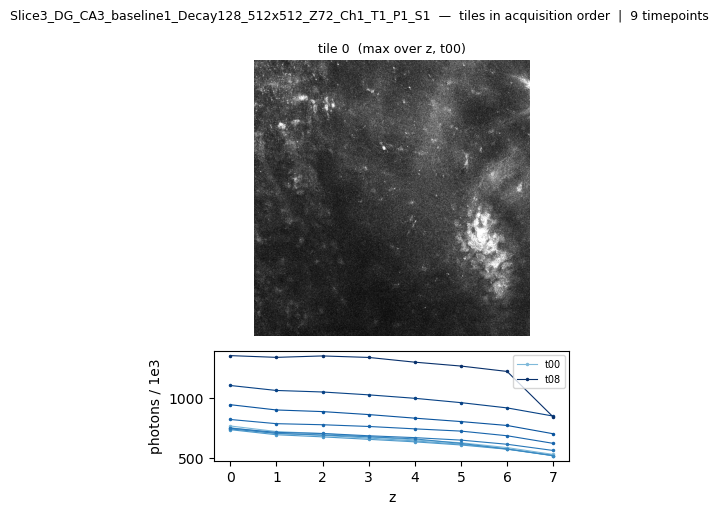

In [18]:
# ── Step 0b: float32 Vista TIFF → uint8 tiles ─────────────────────────────────
conv = vt.convert_to_uint8(raw_path, tiles_dir, n_pos=n_tiles, n_t=n_timepoints, xy_pixel_um=xy_pixel_um,
                           z_step_um=z_step_um, overwrite=rerun_convert)
tile_int_t   = conv['tile_int'].reshape(n_timepoints, n_tiles, *conv['tile_int'].shape[1:])   # (time, tile, z, y, x)
tile_paths_t = [conv['tile_paths'][t * n_tiles:(t + 1) * n_tiles] for t in range(n_timepoints)]
tile_int     = tile_int_t[time_ref]   # (tile, z, y, x) photons summed over bins, file block order (reference timepoint)
_rep = conv['report']
print(f'Corrupted bins zeroed: {100 * _rep["corrupted_fraction"]:.3f}%  |  '
      f'residual junk: {_rep["residual_junk_pixels"]}  |  clipped >255: {_rep["clipped_pixels"]}  |  '
      f'max count/bin/px: {_rep["max_count"]:g}')

# ── dropped planes: true tile / z of every block, from the Olympus tiles of the same scan ──
_ny, _nx  = tile_int.shape[2:]
_empty    = np.flatnonzero(tile_int_t.reshape(n_timepoints * n_tiles * n_z_tile, -1).max(axis=1) == 0)
blk, oir_tiles = None, None
block_of_slot  = None   # None = file layout; else the file block shown at slot tile*n_z + z (-1 = no data)
if (n_timepoints == 1 and matl_info and oir_ch and all(matl_info['files'])
        and (oir_meta['n_z'], oir_meta['ny'], oir_meta['nx']) == tuple(tile_int.shape[1:])):
    oir_tiles = np.stack([oo.read_oir_channel(f, oir_ch['id'], oir_meta['n_z'], oir_meta['ny'], oir_meta['nx'])
                          for f in matl_info['files']])
    blk = vt.align_blocks(tile_int.reshape(-1, _ny, _nx), oir_tiles.reshape(-1, _ny, _nx))
    with open(os.path.join(out_root, f'{vista_info["base"]}_block_map.json'), 'w') as _f:
        json.dump({k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in blk.items() if k != 'ncc_matrix'}, _f)
    _kept = blk['slot_of_block'] >= 0
    print(f'Block check vs Olympus {oir_ch["name"]}: {int(_kept.sum())} of {_kept.size} blocks matched  '
          f'(NCC median {np.nanmedian(blk["ncc"][_kept]):.2f}, min {np.nanmin(blk["ncc"][_kept]):.2f})')
    if blk['shifted'] or blk['missing'].size:
        block_of_slot = blk['block_of_slot']
        _flat = tile_int.reshape(-1, _ny, _nx)
        _true = np.zeros_like(_flat)
        _true[block_of_slot >= 0] = _flat[block_of_slot[block_of_slot >= 0]]
        tile_int = _true.reshape(tile_int.shape)
        _miss = '; '.join(f'tile {t}: z {[int(s % n_z_tile) for s in blk["missing"] if s // n_z_tile == t]}'
                          for t in range(n_tiles) if any(s // n_z_tile == t for s in blk['missing']))
        warnings.warn(f'Vista did not record {blk["missing"].size} of {block_of_slot.size} planes '
                      f'({blk["empty"].size} empty blocks at the end of the file'
                      + (f', {blk["discarded"].size} block(s) straddling a gap discarded: {blk["discarded"].tolist()}'
                         if blk['discarded'].size else '')
                      + '). The recorded blocks were moved to their true tile / z (matched to the Olympus channel); '
                      f'the missing planes stay empty (no photons, coverage 0) -> {_miss}', RuntimeWarning)
    else:
        print('  every block is at its file position: no dropped planes')
elif _empty.size:
    _tt, _r0 = divmod(int(_empty[0]), n_tiles * n_z_tile)
    _t0, _z0 = divmod(_r0, n_z_tile)
    warnings.warn(f'{_empty.size} of {_nb} empty z-blocks (first: ' + (f't{_tt:02d} ' if n_timepoints > 1 else '')
                  + f'tile {_t0} z {_z0}): Vista recorded fewer planes than the microscope acquired. Blocks after the '
                  f'first dropped plane sit at the wrong tile / z and cannot be re-assigned (that needs the Olympus '
                  f'tiles of a single-timepoint scan): registration and stitching are unreliable.', RuntimeWarning)
if n_timepoints > 1 and matl_info and oir_ch:
    print('Olympus block check skipped: time series (reading a time-lapse .oir is not implemented yet)')
if n_timepoints == 1:
    tile_int_t = tile_int[np.newaxis]   # with the blocks at their true tile / z

_ph   = tile_int_t.sum(axis=(3, 4))     # (time, tile, z)
_tcol = plt.cm.Blues(np.linspace(0.45, 1.0, n_timepoints)) if n_timepoints > 1 else ['C0']
fig, axs = plt.subplots(2, n_tiles, figsize=(max(3.2 * n_tiles, 4.5), 5.2), squeeze=False,
                        gridspec_kw=dict(height_ratios=[3, 1.2]))
for p in range(n_tiles):
    _mp = tile_int[p].max(axis=0)
    axs[0, p].imshow(_mp, cmap='gray', vmax=np.percentile(_mp, 99.5))
    axs[0, p].set_title(f'tile {p}  (max over z' + (f', t{time_ref:02d})' if n_timepoints > 1 else ')'), fontsize=9)
    axs[0, p].axis('off')
    for t in range(n_timepoints):
        _lbl = f't{t:02d}' if n_timepoints > 1 and (n_timepoints <= 8 or t in (0, n_timepoints - 1)) else None
        axs[1, p].plot(_ph[t, p] / 1e3, '.-', lw=0.8, ms=3, color=_tcol[t], label=_lbl)
    if block_of_slot is not None:
        _mz = np.flatnonzero(block_of_slot.reshape(n_tiles, n_z_tile)[p] < 0)
        axs[1, p].plot(_mz, np.zeros(_mz.size), 'rx', ms=5, label='not recorded')
    axs[1, p].set_xlabel('z')
axs[1, 0].set_ylabel('photons / 1e3')
if block_of_slot is not None or n_timepoints > 1:
    axs[1, 0].legend(fontsize=7)
plt.suptitle(f'{vista_info["base"]}  —  tiles in acquisition order'
             + (f'  |  {n_timepoints} timepoints' if n_timepoints > 1 else '')
             + ('  (blocks moved to their true tile / z)' if block_of_slot is not None else ''), fontsize=9)
plt.tight_layout()
plt.show()

if blk is not None:   # QC: which Olympus frame each Vista block shows
    _S = blk['ncc_matrix']
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.imshow(_S, aspect='auto', cmap='magma', vmin=0, vmax=0.9, interpolation='nearest')
    ax.plot([0, _S.shape[0] - 1], [0, _S.shape[0] - 1], 'w--', lw=0.6, label='file layout')
    _b = np.flatnonzero(blk['slot_of_block'] >= 0)
    ax.plot(blk['slot_of_block'][_b], _b, 'c.', ms=2, label='assigned tile / z')
    if blk['discarded'].size:
        ax.plot(_S[blk['discarded']].argmax(axis=1), blk['discarded'], 'rx', ms=7, label='discarded (straddles a gap)')
    for t in range(1, n_tiles):
        ax.axvline(t * n_z_tile - 0.5, color='w', lw=0.3)
    ax.set_xlabel(f'Olympus {oir_ch["name"]} frame  (tile x {n_z_tile} + z)')
    ax.set_ylabel('Vista z-block (file order)')
    ax.set_title('NCC: Vista block vs Olympus frame', fontsize=10)
    ax.legend(loc='lower right', fontsize=8)
    plt.tight_layout()
    plt.show()


Registering on: FLIM intensity
Reloaded tile positions <- Slice3_DG_CA3_baseline1_Decay128_512x512_Z72_Ch1_T1_P1_S1_tile_positions.json
Layout single  grid 1 rows x 1 cols  |  canvas (z, y, x) = (8, 512, 512)
Single position: no tile pairs, nothing to register
timepoint    drift_zyx            drift_um  NCC_before  NCC_after
      t00    (0, 0, 0)     (0.0, 0.0, 0.0)       1.000      1.000
      t01    (0, 0, 1)     (0.0, 0.0, 1.0)       0.957      0.958
      t02    (0, 1, 1)     (0.0, 1.0, 1.0)       0.937      0.945
      t03    (0, 1, 1)     (0.0, 1.0, 1.0)       0.935      0.944
      t04    (0, 0, 2)     (0.0, 0.0, 2.0)       0.931      0.942
      t05   (0, -2, 1)    (0.0, -2.0, 1.0)       0.932      0.947
      t06  (-1, -2, 0)   (-8.0, -2.0, 0.0)       0.860      0.950
      t07 (-2, -3, -2) (-16.0, -3.0, -2.0)       0.757      0.934
      t08 (-4, -4, -3) (-32.0, -4.0, -3.0)       0.641      0.905
Canvas of all timepoints (z, y, x) = (12, 517, 517)


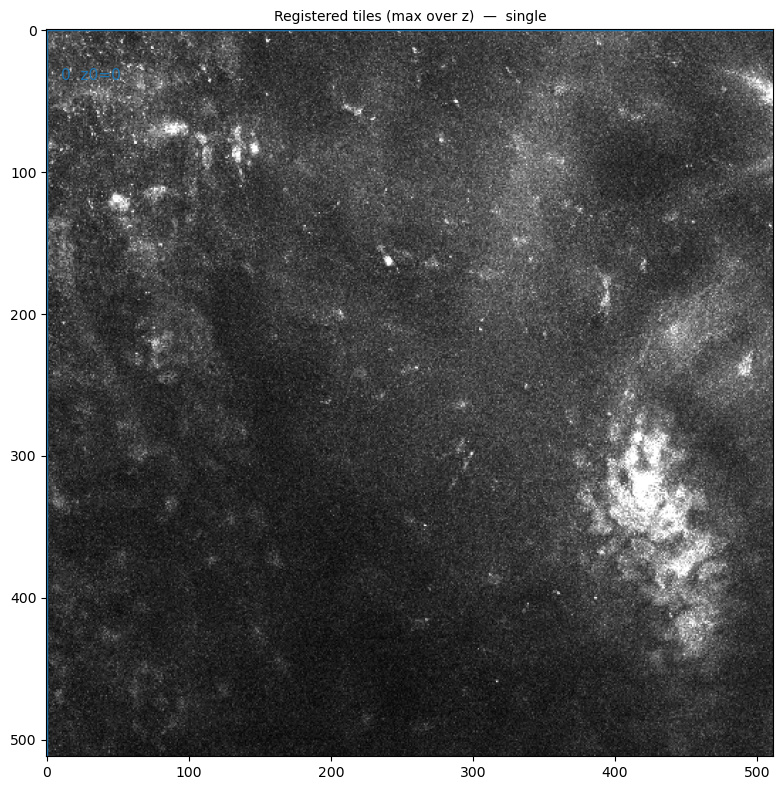

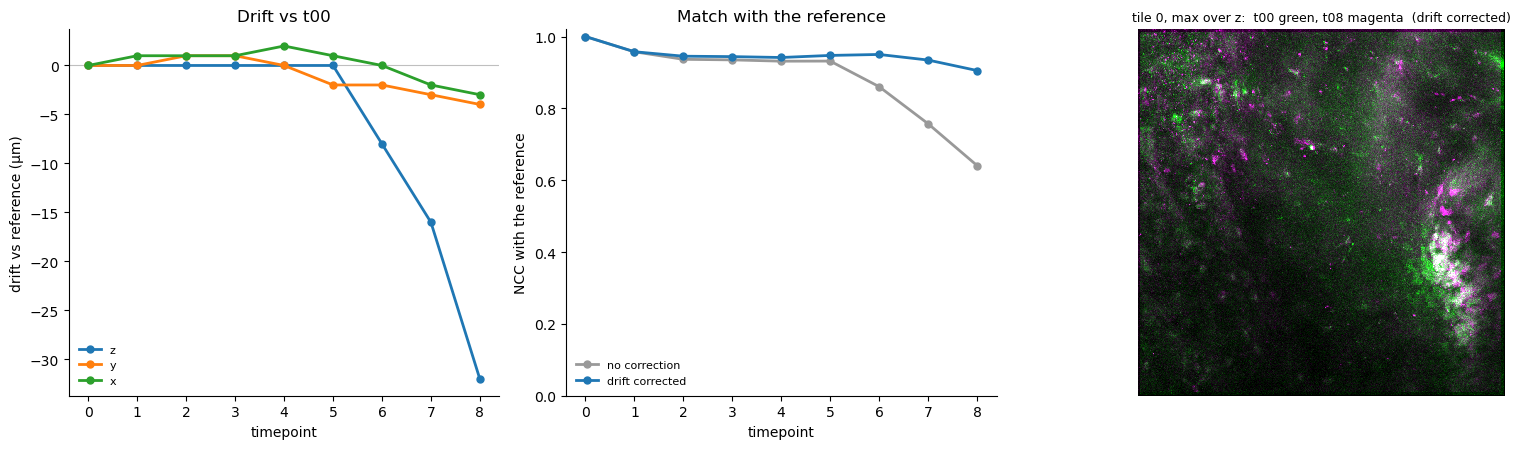

In [19]:
# ── Step 0c: tile registration ────────────────────────────────────────────────
if tile_reg_source not in ('auto', 'flim', 'olympus'):
    raise ValueError(f"tile_reg_source must be 'auto', 'flim' or 'olympus', not {tile_reg_source!r}")
_reg_src = ('olympus' if oir_tiles is not None else 'flim') if tile_reg_source == 'auto' else tile_reg_source
if _reg_src == 'olympus' and oir_tiles is None:
    raise RuntimeError("tile_reg_source='olympus' but this acquisition has no Olympus tiles (Step 0b)")
print(f'Registering on: {"Olympus " + oir_ch["name"] if _reg_src == "olympus" else "FLIM intensity"}')
_bos     = None if block_of_slot is None else [int(b) for b in block_of_slot]
_reg_key = dict(grid=list(tile_grid), overlap=tile_overlap, layout=_reg_layout, fallback=tile_layout_fallback,
                max_dz=max_dz, source=_reg_src, block_of_slot=_bos)     # any change -> register again
if n_timepoints > 1:
    _reg_key.update(n_timepoints=n_timepoints, time_ref=time_ref, time_drift=time_drift, time_max_dz=time_max_dz)
_old_reg = vt.load_tile_positions(pos_json) if os.path.exists(pos_json) else None
if _old_reg is not None and not rerun_register and _old_reg.get('reg_key') == _reg_key:
    tile_reg = _old_reg
    print(f'Reloaded tile positions <- {os.path.basename(pos_json)}')
else:
    if _old_reg is not None and not rerun_register:
        _diff = [k for k in _reg_key if (_old_reg.get('reg_key') or {}).get(k) != _reg_key[k]]
        print(f'Saved tile positions were made with other settings ({", ".join(_diff)}) -> registering again')
    tile_reg = vt.register_tiles(tile_int if _reg_src == 'flim' else oir_tiles.astype(np.float32),
                                 tile_grid, overlap=tile_overlap, layout=_reg_layout,
                                 fallback=tile_layout_fallback, max_dz=max_dz)
    if _reg_src == 'olympus':   # Step 0d normalises the segmentation intensity per FLIM tile
        tile_reg['norm_lo'] = [float(np.percentile(t, 1)) for t in tile_int]
        tile_reg['norm_hi'] = [float(np.percentile(t, 99.5)) for t in tile_int]
    if n_timepoints > 1:   # drift of every timepoint vs time_ref (the tiles keep their registered layout)
        print(f'Drift of {n_timepoints} timepoints vs t{time_ref:02d}'
              + ('' if time_drift else '  (measured, not applied: time_drift=False)'))
        tile_reg['time'] = vt.register_timepoints(tile_int_t, ref=time_ref, max_dz=time_max_dz)
    vt.save_tile_positions(pos_json, tile_reg, raw_path=raw_path, reg_key=_reg_key)
    print(f'Saved -> {pos_json}')
    rerun_fuse = True   # new positions -> re-stitch

_pos = np.array(tile_reg['positions'])
_nz_t, _ny_t, _nx_t = tile_reg['tile_shape']
_Zc, _Yc, _Xc = tile_reg['canvas_shape']
print(f'Layout {tile_reg["layout"]}  grid {tile_reg["grid"][0]} rows x {tile_reg["grid"][1]} cols  |  '
      f'canvas (z, y, x) = {tuple(tile_reg["canvas_shape"])}')
_df_pairs = pd.DataFrame([dict(pair=f'{p["a"]}->{p["b"]}', direction='down' if p['axis'] == 1 else 'right',
                               offset_zyx=tuple(p['offset']), NCC=round(p['score'], 3), used=p['used'],
                               residual_zyx=tuple(p['residual'])) for p in tile_reg['pairs']])
print(_df_pairs.to_string(index=False) if len(_df_pairs) else 'Single position: no tile pairs, nothing to register')
if n_timepoints > 1:   # tile origins of every timepoint on one canvas (Step 0d)
    _tr = tile_reg['time']
    _sh = np.array(_tr['shifts'])
    pos_t, canvas_t = vt.time_positions(tile_reg, _sh if time_drift else np.zeros_like(_sh))
    _um = _sh * np.array([z_step_um, xy_pixel_um, xy_pixel_um])
    print(pd.DataFrame(dict(timepoint=[f't{t:02d}' for t in range(n_timepoints)],
                            drift_zyx=[tuple(int(v) for v in s) for s in _sh],
                            drift_um=[tuple(round(float(v), 1) for v in u) for u in _um],
                            NCC_before=np.round(_tr['ncc0'], 3), NCC_after=np.round(_tr['ncc'], 3))).to_string(index=False))
    print(f'Canvas of all timepoints (z, y, x) = {tuple(canvas_t)}' + ('' if time_drift else '  (drift NOT applied)'))

# QC: max-projection preview on the canvas with tile outlines
_prev = np.zeros((_Yc, _Xc), np.float32)
for p in range(n_tiles):
    _n = (tile_int[p].max(axis=0) - tile_reg['norm_lo'][p]) / max(tile_reg['norm_hi'][p] - tile_reg['norm_lo'][p], 1e-9)
    _y0, _x0 = _pos[p, 1], _pos[p, 2]
    _sub = _prev[_y0:_y0 + _ny_t, _x0:_x0 + _nx_t]
    np.maximum(_sub, _n, out=_sub)
fig, ax = plt.subplots(figsize=(8, 8 * _Yc / _Xc))
ax.imshow(_prev, cmap='gray', vmin=0, vmax=np.percentile(_prev, 99.5))
for p in range(n_tiles):
    ax.add_patch(plt.Rectangle((_pos[p, 2], _pos[p, 1]), _nx_t, _ny_t, fill=False, ec=f'C{p}', lw=1))
    ax.text(_pos[p, 2] + 10, _pos[p, 1] + 35, f'{p}  z0={_pos[p, 0]}', color=f'C{p}', fontsize=11)
ax.set_title(f'Registered tiles (max over z)  —  {tile_reg["layout"]}', fontsize=10)
plt.tight_layout()
plt.show()

if n_timepoints > 1:   # QC: drift per timepoint, and the most-drifted timepoint on the reference
    _tw = int(np.argmax(np.abs(_sh).sum(axis=1)))
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw=dict(width_ratios=[1, 1, 1.2]))
    for _k, _ax_name in enumerate(('z', 'y', 'x')):
        axs[0].plot(_um[:, _k], 'o-', lw=2, ms=5, color=f'C{_k}', label=_ax_name)
    axs[0].axhline(0, color='0.75', lw=0.8, zorder=0)
    axs[0].set(xlabel='timepoint', ylabel='drift vs reference (µm)', title=f'Drift vs t{time_ref:02d}')
    axs[1].plot(_tr['ncc0'], 'o-', lw=2, ms=5, color='0.6', label='no correction')
    axs[1].plot(_tr['ncc'], 'o-', lw=2, ms=5, color='C0', label='drift corrected')
    axs[1].set(xlabel='timepoint', ylabel='NCC with the reference', title='Match with the reference', ylim=(0, 1.02))
    for _a in axs[:2]:
        _a.set_xticks(range(n_timepoints))
        _a.spines[['top', 'right']].set_visible(False)
        _a.legend(fontsize=8, frameon=False)
    _ov = np.zeros((2, canvas_t[1], canvas_t[2]), np.float32)
    for _i, _t in enumerate((time_ref, _tw)):
        _m = tile_int_t[_t, 0].max(axis=0)
        _lo, _hi = np.percentile(_m, [1, 99.7])
        _y0, _x0 = pos_t[_t, 0, 1], pos_t[_t, 0, 2]
        _ov[_i, _y0:_y0 + _ny_t, _x0:_x0 + _nx_t] = np.clip((_m - _lo) / max(_hi - _lo, 1e-9), 0, 1)
    axs[2].imshow(np.dstack([_ov[1], _ov[0], _ov[1]]), interpolation='nearest')
    axs[2].set_title(f'tile 0, max over z:  t{time_ref:02d} green, t{_tw:02d} magenta  '
                     f'({"drift corrected" if time_drift else "NOT corrected"})', fontsize=9)
    axs[2].axis('off')
    plt.tight_layout()
    plt.show()

### Step 0d: time sum and per-timepoint TCSPC stacks on one canvas
Every timepoint (and tile) goes onto one canvas at its drift-corrected whole-voxel position from Step 0c, so a canvas
voxel is the same spot in the tissue at every timepoint. The decays are only moved, never interpolated, and the photon
count is checked (fused = tiles). The canvas is larger than one stack by the drift range.
- **Time sum** → `analysis/stitched/` (`data_folder` of Steps 1–16): per voxel, the decays of all timepoints (and overlapping
  tiles) summed as raw counts; one `TYX` TIFF per z (`<base>_stitched_Z###.tif`, uint8, uint16 if a voxel exceeds 255).
- **Each timepoint** → `analysis/stitched_timepoints/T<tt>/` (Step 17): same canvas, that timepoint's photons only
  (`<base>_T<tt>_stitched_Z###.tif`).
- **Segmentation reference** `analysis/intensity_coverage/<base>_photonsum.tif` (Step 2): Σ photons ÷ Σ brightness *b* of
  the timepoints × tiles covering each voxel (*b* = mean photons of that timepoint × tile on the tissue all timepoints
  share; tile overlaps feather-blended). Where every timepoint covers a voxel it is the photon sum ÷ a constant:
  brighter timepoints weigh more (e.g. Peredox cpGFP brightening on NADH binding) and nothing is rescaled per
  timepoint. At the drift edges it keeps the same level where a plain sum would dim.
- **Display intensity** `<base>_stitched_intensity.tif`: every timepoint and tile scaled to its own 1–99.5 % range,
  then feather-blended (an average; Step 0e check). Step 2's segmentation input until 2026-11-20.
- **Coverage** `intensity_coverage/<base>_coverage.tif`: timepoints × tiles per voxel (per timepoint:
  `<base>_T<tt>_coverage.tif`, next to `<base>_T<tt>_stitched_intensity.tif`). At the canvas edges drift leaves fewer timepoints,
  so the time sum has fewer photons there; Step 17 uses the per-timepoint coverage for `fov_frac`.

Files go to `analysis/` in the raw file's folder and are reused when present; new positions from 0c or `rerun_fuse = True` rebuild them.
Disk: the timepoint stacks take about as much as the converted tiles, the sum one stack more.
With `n_timepoints = 1` this is the plain tile stitch.

Reusing stitched planes in D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\analysis\stitched
Reusing stitched planes in D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\analysis\stitched_timepoints\T00
Reusing stitched planes in D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\analysis\stitched_timepoints\T01
Reusing stitched planes in D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\analysis\stitched_timepoints\T02
Reusing stitched planes in D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\analysis\stitched_timepoints\T03
Reusing stitched planes in D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\analysis\stitched_timepoints\T04
Reusing stitched planes in D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\analysis\stitched_timepoints\T05
Reusing stitched planes in D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\analysis\stitched_timepoints\T06
Reusing stitched planes in D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\analysis\stitched_timepoints\T07
Reusing stitched planes in D:\Yu_B

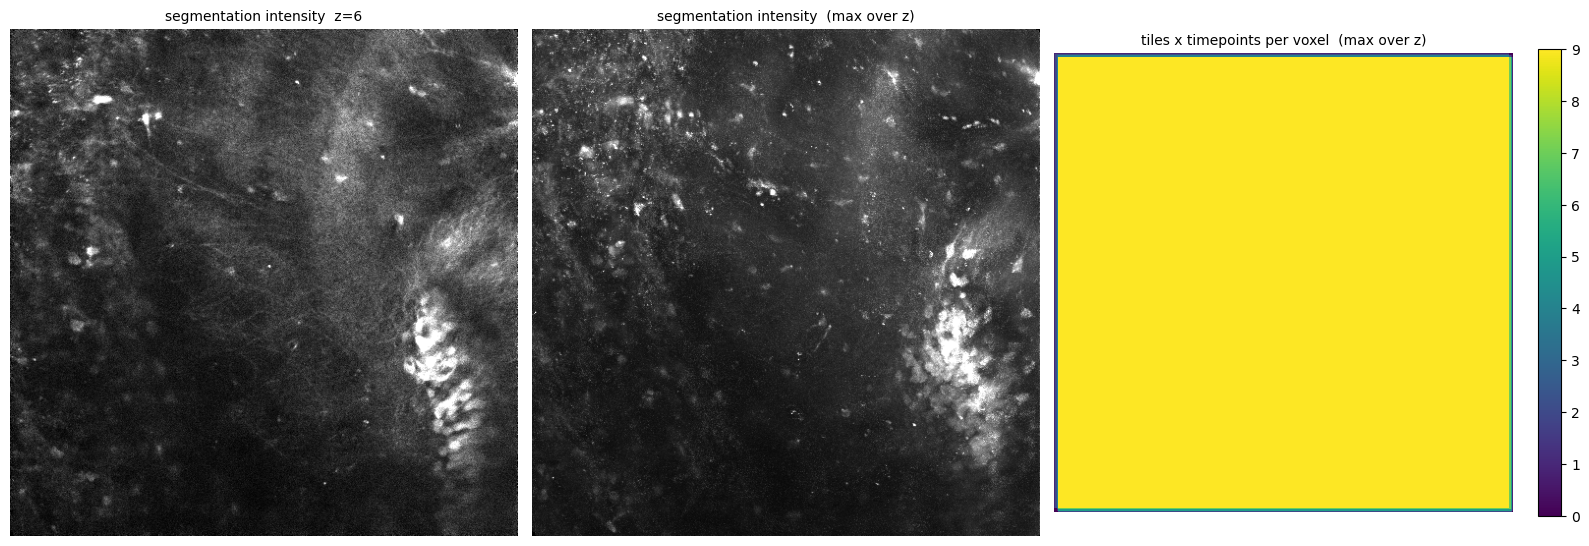

data_folder for Steps 1-16: D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\analysis\stitched  (12 planes, sum of 9 timepoints)
Intensity / coverage: D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\analysis\intensity_coverage
Per timepoint (Step 17): D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\analysis\stitched_timepoints  (T00, T01, T02, T03, T04, T05, T06, T07, T08)
  photons per timepoint: t00 5.25M  t01 5.15M  t02 5.09M  t03 5.18M  t04 5.34M  t05 5.91M  t06 6.69M  t07 7.96M  t08 10.00M


In [20]:
# ── Step 0d: stitched TCSPC (overlaps summed) + segmentation intensity ─────────
stitch_t = None    # per-timepoint stacks of a time series (Step 17)
if n_timepoints == 1:
    stitch = vt.fuse_tiles(conv['tile_paths'], tile_reg, tile_int, out_root, vista_info['base'],
                           overwrite=rerun_fuse, block_of_slot=block_of_slot, int_dir=int_dir)
else:   # one canvas for all timepoints: their sum -> stitched/ (Steps 1-16), timepoint t -> stitched_timepoints/T<tt>/ (Step 17)
    _ti_flat = tile_int_t.reshape(-1, *tile_int_t.shape[2:])
    _lo = [float(np.percentile(v, 1)) for v in _ti_flat]       # per tile and timepoint (bleaching)
    _hi = [float(np.percentile(v, 99.5)) for v in _ti_flat]
    stitch = vt.fuse_tiles(sum(tile_paths_t, []),
                           dict(tile_reg, positions=pos_t.reshape(-1, 3).tolist(), canvas_shape=canvas_t,
                                norm_lo=_lo, norm_hi=_hi),
                           _ti_flat, out_root, vista_info['base'], overwrite=rerun_fuse, int_dir=int_dir)
    stitch_t = []
    for t in range(n_timepoints):
        _s = slice(t * n_tiles, (t + 1) * n_tiles)
        stitch_t.append(vt.fuse_tiles(tile_paths_t[t],
                                      dict(tile_reg, positions=pos_t[t].tolist(), canvas_shape=canvas_t,
                                           norm_lo=_lo[_s], norm_hi=_hi[_s]),
                                      tile_int_t[t], out_root, f'{vista_info["base"]}_T{t:02d}',
                                      overwrite=rerun_fuse, stitched_name=os.path.join(tp_dir, f'T{t:02d}'),
                                      int_dir=int_dir))
stitched_dir = stitch['stitched_dir']

# ── segmentation reference (Step 2): Σ photons / Σ brightness of the timepoints x tiles covering each voxel ──
canvas_pos = np.asarray(pos_t if n_timepoints > 1 else [tile_reg['positions']], int)   # (time, tile, zyx) origins
canvas_shp = tuple(int(v) for v in (canvas_t if n_timepoints > 1 else tile_reg['canvas_shape']))
seg_ref, seg_ntp, seg_b = vt.photon_sum_reference(tile_int_t, canvas_pos, canvas_shp)
seg_ref_path = os.path.join(int_dir, f'{vista_info["base"]}_photonsum.tif')
if not (os.path.exists(seg_ref_path) and np.array_equal(tifffile.imread(seg_ref_path), seg_ref)):
    tifffile.imwrite(seg_ref_path, seg_ref)   # rewritten only when it changes (the Step 2 caches check its date)

_fi  = seg_ref
_cov = tifffile.imread(stitch['cov_path'])
if _fi.shape != _cov.shape:
    raise ValueError(f'segmentation reference {_fi.shape} != stitched canvas {_cov.shape}: rerun_fuse = True')
_zm  = _fi.shape[0] // 2
fig, axs = plt.subplots(1, 3, figsize=(16, 7))
for _a, _img, _ttl in [(axs[0], _fi[_zm], f'segmentation reference (photon sum / brightness)  z={_zm}'),
                       (axs[1], _fi.max(axis=0), 'segmentation reference  (max over z)')]:
    _a.imshow(_img, cmap='gray', vmin=0, vmax=np.percentile(_img, 99.5))
    _a.set_title(_ttl, fontsize=10); _a.axis('off')
_im = axs[2].imshow(_cov.max(axis=0), cmap='viridis', interpolation='nearest')
axs[2].set_title(('tiles x timepoints' if n_timepoints > 1 else 'tiles') + ' per voxel  (max over z)', fontsize=10)
axs[2].axis('off')
plt.colorbar(_im, ax=axs[2], fraction=0.046)
plt.tight_layout()
plt.show()
print(f'data_folder for Steps 1-16: {stitched_dir}  ({len(stitch["plane_paths"])} planes'
      + (f', sum of {n_timepoints} timepoints)' if n_timepoints > 1 else ')'))
print(f'Intensity / coverage: {int_dir}  (segmentation reference: {os.path.basename(seg_ref_path)})')
if n_timepoints > 1:
    print('  brightness per timepoint (mean photons on the shared tissue / mean' + (', tile 0' if n_tiles > 1 else '')
          + '): ' + '  '.join(f't{t:02d} {r:.2f}' for t, r in enumerate((seg_b / seg_b.mean(axis=0))[:, 0])))
if stitch_t:
    print(f'Per timepoint (Step 17): {tp_dir}  ({", ".join(os.path.basename(s["stitched_dir"]) for s in stitch_t)})')
    print('  photons per timepoint: ' + '  '.join(f't{t:02d} {v / 1e6:.2f}M'
                                                  for t, v in enumerate(tile_int_t.sum(axis=(1, 2, 3, 4)))))

### Step 0e: Olympus PMT channel stitched with the TCSPC tile positions
Both detectors record the same scan, so the Olympus tiles take the tile positions of Step 0c. Their pixel offset to the
TCSPC tiles (detector timing, typically ~1 px in x) is measured per tile by phase correlation and its median is
corrected (`oir_align`, linear interpolation). The per-tile NCC with the FLIM intensity checks the tile pairing.
Output: `analysis/intensity_coverage/<base>_stitched_<CH>.tif` (z, y, x; per-tile normalised, feather-blended) + `.json` report.


In [21]:
# ── Step 0e: Olympus PMT channel (e.g. mCherry) stitched with the same tile positions ──
oir_align = True    # correct the measured Olympus-vs-TCSPC pixel offset (one sub-pixel shift for all tiles)
rerun_oir = False

stitch_oir = None   # stitched Olympus channel; None -> Step 2 segments the FLIM intensity
if not (matl_info and oir_ch):
    print('Step 0e skipped: no Olympus multi-area tiles (matl.omp2info + .oir) for this acquisition.')
elif n_timepoints > 1:
    print('Step 0e skipped: time series (reading a time-lapse .oir is not implemented yet).')
elif not all(matl_info['files']):
    print(f'Step 0e skipped: missing .oir tiles {[p for p, f in enumerate(matl_info["files"]) if not f]}')
elif (oir_meta['n_z'], oir_meta['ny'], oir_meta['nx']) != tuple(tile_int.shape[1:]):
    print(f'Step 0e skipped: Olympus tiles {(oir_meta["n_z"], oir_meta["ny"], oir_meta["nx"])} != '
          f'TCSPC tiles {tuple(tile_int.shape[1:])}')
else:
    stitch_oir = os.path.join(int_dir, f'{vista_info["base"]}_stitched_{oir_ch["name"]}.tif')
    _oir_json  = stitch_oir.replace('.tif', '.json')
    _old = json.load(open(_oir_json)) if os.path.exists(_oir_json) else {}
    if (not rerun_oir and os.path.exists(stitch_oir) and _old.get('channel') == oir_ch['id']
            and _old.get('aligned') == oir_align and os.path.getmtime(stitch_oir) > os.path.getmtime(pos_json)):
        oir_report = _old
        print(f'Reusing {os.path.basename(stitch_oir)}')
    else:
        _oir_tiles = oir_tiles if oir_tiles is not None else np.stack(
            [oo.read_oir_channel(f, oir_ch['id'], oir_meta['n_z'], oir_meta['ny'], oir_meta['nx'])
             for f in matl_info['files']])
        oir_report = vt.channel_offset(tile_int, _oir_tiles)
        vt.fuse_intensity(_oir_tiles, tile_reg, stitch_oir, shift_yx=oir_report['offset'] if oir_align else None)
        oir_report.update(channel=oir_ch['id'], channel_name=oir_ch['name'], filter=oir_ch['filter'],
                          aligned=oir_align, files=matl_info['files'],
                          saturated_px=int((_oir_tiles >= 2 ** (oir_meta['bit_depth'] or 16) - 1).sum()))
        with open(_oir_json, 'w') as _f:
            json.dump(oir_report, _f, indent=1)
        del _oir_tiles
        print(f'Saved -> {stitch_oir}')
    _dy, _dx = oir_report['offset']
    print(f'{oir_ch["name"]} vs TCSPC pixel offset (dy, dx) = ({_dy:+.2f}, {_dx:+.2f}) px  '
          f'(MAD {oir_report["spread"][0]:.2f}, {oir_report["spread"][1]:.2f})  -> '
          f'{"corrected" if oir_align else "NOT corrected (oir_align=False)"}  |  saturated px: {oir_report["saturated_px"]}')
    print('  per tile (dy, dx): ' + '  '.join(f'{p}:({a:+.1f},{b:+.1f})' for p, (a, b) in enumerate(oir_report['per_tile'])))
    print('  NCC with the FLIM intensity, before -> after shift: ' +
          '  '.join(f'{p}:{a:.2f}->{b:.2f}' for p, (a, b) in enumerate(zip(oir_report['ncc_before'], oir_report['ncc_after']))))
    if min(oir_report['ncc_after']) < 0.3:
        warnings.warn('An Olympus tile matches its TCSPC tile poorly (NCC < 0.3): check the tile pairing / order',
                      RuntimeWarning)

    # QC: FLIM intensity vs Olympus channel, middle plane + overlay
    _ri = tifffile.imread(stitch_oir)
    _gi = tifffile.imread(stitch['int_path'])
    _zm = _ri.shape[0] // 2
    _n01 = lambda im: np.clip((im - np.percentile(im, 1)) / (np.percentile(im, 99.7) - np.percentile(im, 1)), 0, 1)
    _g, _r = _n01(_gi[_zm]), _n01(_ri[_zm])
    _ov = np.dstack([_r, _g, _r])                      # FLIM green, Olympus magenta, overlap white
    _cy, _cx = np.unravel_index(np.argmax(gaussian_filter(_r, 20)), _r.shape)
    _cy = int(np.clip(_cy, 75, _r.shape[0] - 75)); _cx = int(np.clip(_cx, 75, _r.shape[1] - 75))
    fig, axs = plt.subplots(1, 4, figsize=(22, 6.5 * _r.shape[0] / _r.shape[1] / 1.1))
    for _a, _img, _ttl in [(axs[0], _g, f'FLIM intensity  z={_zm}'),
                           (axs[1], _r, f'Olympus {oir_ch["name"]} ({oir_ch["filter"]})  z={_zm}'),
                           (axs[2], _ov, 'overlay: FLIM green / Olympus magenta'),
                           (axs[3], _ov[_cy - 75:_cy + 75, _cx - 75:_cx + 75], f'overlay zoom (150 px at y={_cy}, x={_cx})')]:
        _a.imshow(_img, cmap='gray', interpolation='nearest')
        _a.set_title(_ttl, fontsize=10); _a.axis('off')
    axs[2].add_patch(plt.Rectangle((_cx - 75, _cy - 75), 150, 150, fill=False, ec='y', lw=1))
    plt.tight_layout()
    plt.show()


Step 0e skipped: time series (reading a time-lapse .oir is not implemented yet).


## Step 1: Parameters & data loading
Edit the analysis parameters, then run the cell. `data_folder` is the `analysis/stitched/` folder from Step 0d (the dated `*_FLIM_Analysis` results folder is created inside it); voxel size and `Tcycle` come from Step 0a.
Set `dim_data` / `dim_irf` to match your TIFF axis order if needed.

| Variable | Shape | Description |
|----------|-------|-------------|
| `DataTCSPC` | `(ny, nx, nbin)` | TCSPC photon counts after reorder |
| `IRF` | `(nbin,)` | Instrument Response Function (summed to 1-D) |
| `sumTCSPC` | `(ny, nx)` | Total photons per pixel |
| `maskPMT` | `(ny, nx)` | 1 = valid pixel (counts > threshold), NaN = masked |

  Reusing existing analysis folder:D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\analysis\stitched\20261118_1559_FLIM_Analysis
  → Cached files (.npz, .csv) in this folder will be loaded by later steps.
  → Set  force_new_analysis = True  to start a fresh dated folder.
  IRF:         D:\Peredox_FLIM\Urea_SHG_IRF_FLIM_980nm_4_Decay128_512x512_Z1_Ch1_T1_P1_S1.tif
  Data folder: D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\analysis\stitched
  FName:       Slice3_DG_CA3_baseline1_Decay128_512x512_Z72_Ch1_T1_P1_S1

Found 12 planes in:  D:\Yu_Brain_slices\Slice3_DG_CA3_baseline1_Cycle\analysis\stitched
Middle plane  z=6:  Slice3_DG_CA3_baseline1_Decay128_512x512_Z72_Ch1_T1_P1_S1_stitched_Z006.tif

  No .fbs.xml found for IRF

Data metadata: Slice3_DG_CA3_baseline1.fbs.xml
  Tcycle=12.4976 ns  nbin=128  gain=62%  dwell=0.0020000000949949026 ms/px  excitation=780 nm
Voxel size:  xy=0.994368911043582 µm   z=8.0 µm   anisotropy=8.05

Middle-plane DataTCSPC shape: (517, 517, 128)  (ny, nx,

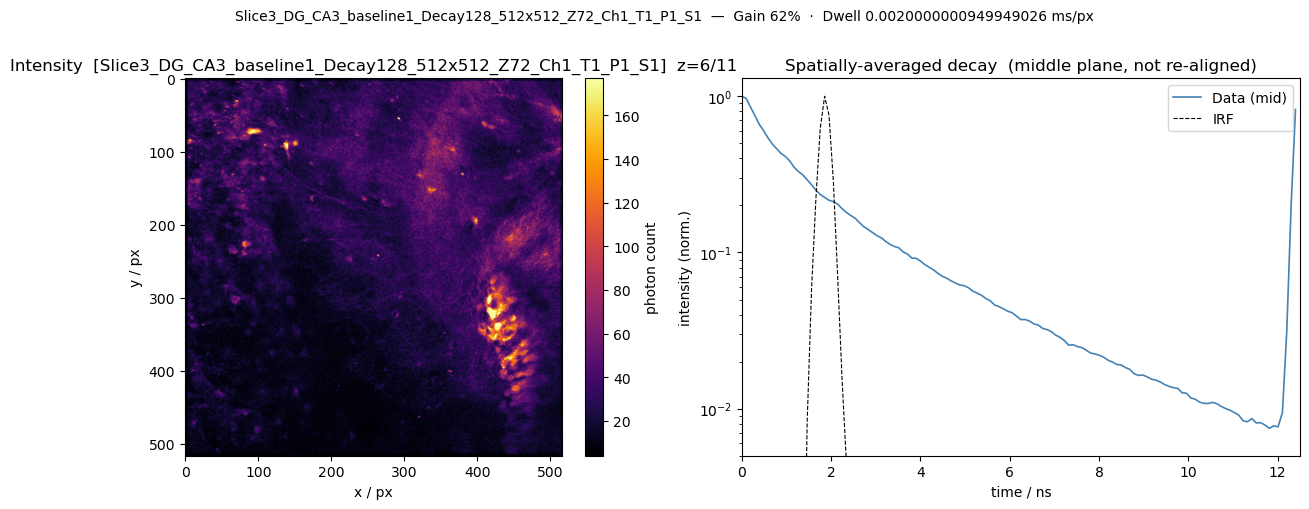

In [23]:
# ── analysis parameters (edit per experiment) ─────────────────────────────────
# Tcycle, xy_pixel_um, z_step_um: set in Step 0a (ISS .fbs.xml / Olympus .oir metadata, or the defaults)
threshold = 3
limits    = np.array([np.nan, np.nan])
szPhs     = 0.005
szBin     = 3

# ── voxel dimensions (µm): xy_pixel_um / z_step_um set in Step 0a ─────────────

# ── mask pre-processing (Step 2; tuned 2026-11-20, see Step 2) ──────────────────
thresh_norm    = 0.6           # intensity mask = vol_norm_3d >= thresh_norm (Step 3 adds the cells -> mask3d)
mask_smooth_um = 0.7           # Gaussian sigma in xy (µm) before NLM; 0 = none
nlm_mode       = '2d'          # NLM per plane ('2d'), on the volume ('3d'), or None
nlm_hfac       = 3.0           # NLM strength h = nlm_hfac x estimated noise sigma
nlm_patch_size = 5
nlm_patch_dist = 6
nlm_fast       = True
bg_mode        = 'ellipsoid'   # background: 'ellipsoid' (rolling ball scaled to the data), 'ball', 'gauss', None
bg_um          = 40.0          # background scale (µm): ball radius / Gaussian sigma, >> cell size
bg_height      = 1.0           # 'ellipsoid' height in normalised intensity (data 0..1); lower removes more
# before 2026-11-20: 3D NLM h 0.8 sigma, no smoothing, 'ball' radius 30 px, thresh_norm 0.55

Data_path_main = os.path.normpath(r"D:\Peredox_FLIM\XYZT1_336_X+0.50_Y+0.80_Decay128_512x512_Z186_Ch1_T1_P1_S1\XYZT1_336_X+0.50_Y+0.80_Decay128_512x512_Z186_Ch1_T1_P1_S1.tif")

# ── TIFF dimension order ───────────────────────────────────────────────────────
dim_data = 'TYX'
dim_irf  = 'TYX'

# ── file / folder pickers (uncomment for interactive selection) ───────────────
def _pick_file(title):
    root = tk.Tk(); root.withdraw(); root.attributes('-topmost', True)
    p = filedialog.askopenfilename(
        title=title, filetypes=[('TIFF files', '*.tif *.tiff'), ('All files', '*.*')])
    root.destroy()
    return p or None

def _pick_folder(title, initialdir=Data_path_main):
    # On Windows, askdirectory ignores initialdir for mapped network drives.
    # Temporarily chdir there so the dialog opens in the right place.
    _init = initialdir
    while _init and not os.path.isdir(_init):
        _parent = os.path.dirname(_init)
        if _parent == _init:
            _init = None; break
        _init = _parent
    _cwd = os.getcwd()
    if _init:
        os.chdir(_init)
    try:
        root = tk.Tk(); root.withdraw(); root.attributes('-topmost', True)
        p = filedialog.askdirectory(title=title, initialdir=_init)
        root.destroy()
    finally:
        os.chdir(_cwd)   # always restore kernel working directory
    return p or None

# ── paths — swap comments to switch between hardcoded and interactive ─────────
irf_path    = r"D:\Peredox_FLIM\Urea_SHG_IRF_FLIM_980nm_4_Decay128_512x512_Z1_Ch1_T1_P1_S1.tif"
# irf_path    = _pick_file('Select IRF TIFF')
data_folder = stitched_dir   # stitched TCSPC planes from Step 0d
# data_folder = _pick_folder('Select folder containing data TIFFs (z-stack)', initialdir=r'X:\FLIM_2026\test_data')

if not data_folder:
    raise RuntimeError('No data folder selected.')

# ── FName from the raw Vista file name ────────────────────────────────────────
FName = vista_info['base']

# ── analysis folder: reuse most recent or create new ─────────────────────────
force_new_analysis = False   # set True to always create a fresh dated folder

_existing = sorted(
    [d for d in glob.glob(os.path.join(data_folder, '*_FLIM_Analysis'))
     if os.path.isdir(d)]
)   # lexicographic sort == chronological (YYYYMMDD_HHMM prefix)

if _existing and not force_new_analysis:
    newFolder = _existing[-1]   # most recent
    print(f'  Reusing existing analysis folder:{newFolder}')
    print('  → Cached files (.npz, .csv) in this folder will be loaded by later steps.')
    print('  → Set  force_new_analysis = True  to start a fresh dated folder.')
else:
    _ts       = datetime.now().strftime('%Y%m%d_%H%M')
    newFolder = os.path.join(data_folder, f'{_ts}_FLIM_Analysis')
    os.makedirs(newFolder, exist_ok=True)
    if force_new_analysis and _existing:
        print(f'  Created new analysis folder (force_new_analysis=True):{newFolder}')
    else:
        print(f'  Created analysis folder:{newFolder}')

print(f'  IRF:         {irf_path}')
print(f'  Data folder: {data_folder}')
print(f'  FName:       {FName}')

# ── natural sort ──────────────────────────────────────────────────────────────
def _natural_key(s):
    return [int(c) if c.isdigit() else c.lower() for c in re.split(r'(\d+)', s)]

# ── XML search helper ─────────────────────────────────────────────────────────
def _find_xml(tiff_path):
    base = re.sub(r'_Intensity.*$', '', os.path.splitext(os.path.basename(tiff_path))[0])
    for search_dir in [os.path.dirname(os.path.dirname(tiff_path)), os.path.dirname(tiff_path)]:
        hits = sorted(glob.glob(os.path.join(search_dir, '*.fbs.xml')))
        if hits:
            return max(hits, key=lambda p: len(os.path.commonprefix([base, os.path.basename(p)])))
    return None

# ── axis-reorder helper ───────────────────────────────────────────────────────
def _to_yxt(arr, order):
    order = list(order.upper())
    extra = [i for i, c in enumerate(order) if c not in ('T', 'Y', 'X')]
    if extra:
        arr   = arr.sum(axis=tuple(sorted(extra)))
        order = [c for c in order if c in ('T', 'Y', 'X')]
    y, x, t = order.index('Y'), order.index('X'), order.index('T')
    return np.transpose(arr, [y, x, t])

# ── enumerate z-planes ────────────────────────────────────────────────────────
data_paths = sorted(
    glob.glob(os.path.join(data_folder, '*.tif')) +
    glob.glob(os.path.join(data_folder, '*.tiff')),
    key=_natural_key)
n_planes = len(data_paths)
mid_idx  = n_planes // 2
print(f'\nFound {n_planes} planes in:  {data_folder}')
print(f'Middle plane  z={mid_idx}:  {os.path.basename(data_paths[mid_idx])}')

# ── load IRF metadata ─────────────────────────────────────────────────────────
meta_irf = None
xml_irf  = _find_xml(irf_path)
if xml_irf:
    meta_irf = read_fbs_metadata(xml_irf)
    print(f'\nIRF metadata:  {os.path.basename(xml_irf)}')
    print(f'  Tcycle={meta_irf["Tcycle"]:.4f} ns  nbin={meta_irf["nbin"]}  '
          f'gain={meta_irf["detector_gain"]}%  dwell={meta_irf["dwell_time_ms"]} ms/px')
else:
    print('\n  No .fbs.xml found for IRF')

# ── data metadata: the ISS .fbs.xml found in Step 0a (Tcycle is set there) ────
# Its ImageRegion is a Vista placeholder (±50 µm), so the voxel size stays the Step 0a one.
meta = fbs_meta
if meta:
    print(f'\nData metadata: {os.path.basename(fbs_xml)}')
    print(f'  Tcycle={Tcycle:.4f} ns  nbin={meta["nbin"]}  '
          f'gain={meta["detector_gain"]}%  dwell={meta["dwell_time_ms"]} ms/px  '
          f'excitation={meta["excitation_nm"]} nm')
else:
    print(f'\n  No .fbs.xml for the data — Tcycle = {Tcycle} ns (Step 0a default)')

print(f'Voxel size:  xy={xy_pixel_um} µm   z={z_step_um} µm   '
      f'anisotropy={z_step_um/xy_pixel_um:.2f}')

# ── Tcycle cross-check ────────────────────────────────────────────────────────
if meta_irf and meta:
    _dt = abs(meta_irf['Tcycle'] - meta['Tcycle'])
    if _dt > 0.01:
        warnings.warn(
            f'Tcycle mismatch: IRF={meta_irf["Tcycle"]:.4f} ns, '
            f'data={meta["Tcycle"]:.4f} ns (diff={_dt:.4f} ns). Using data Tcycle.',
            RuntimeWarning, stacklevel=2)
        print(f'WARNING: Tcycle mismatch — IRF={meta_irf["Tcycle"]:.4f}, data={meta["Tcycle"]:.4f} ns')
    else:
        print(f'\nTcycle cross-check OK  ({meta_irf["Tcycle"]:.4f} vs {meta["Tcycle"]:.4f} ns,  '
              f'diff={_dt:.5f} ns)')
elif meta_irf and not meta:
    print(f'IRF XML period {meta_irf["Tcycle"]:.4f} ns  (data: Step 0a default {Tcycle} ns, not overridden)')

_gain  = f"Gain {meta['detector_gain']}%"        if meta and meta['detector_gain']  is not None else ''
_dwell = f"Dwell {meta['dwell_time_ms']} ms/px"   if meta and meta['dwell_time_ms'] is not None else ''
meta_str = '  ·  '.join(s for s in [_gain, _dwell] if s)

# ── load IRF (1-D) ────────────────────────────────────────────────────────────
IRF_raw = tifffile.imread(irf_path).astype(float)
IRF = (_to_yxt(IRF_raw, dim_irf).sum(axis=(0, 1))
       if any(c in dim_irf.upper() for c in ('Y', 'X')) else IRF_raw.ravel())

# ── load middle plane as reference DataTCSPC ─────────────────────────────────
data_raw  = tifffile.imread(data_paths[mid_idx]).astype(float)
DataTCSPC = _to_yxt(data_raw, dim_data)
print(f'\nMiddle-plane DataTCSPC shape: {DataTCSPC.shape}  (ny, nx, nbin)')

# ── nbin check ────────────────────────────────────────────────────────────────
nbin_data = DataTCSPC.shape[2]
for _label, _m in [('data XML', meta), ('IRF XML', meta_irf)]:
    if _m and _m['nbin'] is not None and nbin_data != _m['nbin']:
        warnings.warn(
            f'nbin mismatch ({_label}): data has {nbin_data} bins, XML says {_m["nbin"]}.',
            RuntimeWarning, stacklevel=2)
print(f'nbin = {nbin_data}  ✓')

sumTCSPC = DataTCSPC.sum(axis=2)
maskPMT  = (sumTCSPC >= threshold).astype(float)
maskPMT[maskPMT == 0] = np.nan

_flat  = sumTCSPC.ravel(); _flat = _flat[_flat > 0]
lo_pct = np.percentile(_flat, 1)
hi_pct = np.percentile(_flat, 99.9)

_nbin_d  = DataTCSPC.shape[2]
_tau_d   = np.arange(_nbin_d) * (Tcycle / _nbin_d)
_decay   = DataTCSPC.sum(axis=(0, 1)).astype(float)
_irf_d   = IRF[:_nbin_d] / IRF[:_nbin_d].max()
_decay_n = _decay / _decay.max()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
im = axes[0].imshow(sumTCSPC, cmap='inferno', aspect='equal', origin='upper',
                    vmin=lo_pct, vmax=hi_pct)
axes[0].set_title(f'Intensity  [{FName}]  z={mid_idx}/{n_planes-1}', fontsize=12)
axes[0].set_xlabel('x / px'); axes[0].set_ylabel('y / px')
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04).set_label('photon count')
axes[1].semilogy(_tau_d, _decay_n, color='steelblue', linewidth=1.2, label='Data (mid)')
axes[1].semilogy(_tau_d, _irf_d,   color='k', linewidth=0.8, linestyle='--', label='IRF')
axes[1].set_xlabel('time / ns'); axes[1].set_ylabel('intensity (norm.)')
axes[1].set_title('Spatially-averaged decay  (middle plane, not re-aligned)', fontsize=12)
axes[1].set_xlim(0, Tcycle); axes[1].set_ylim(5e-3, 1.3)
axes[1].legend()
_suptitle = FName + (f'  —  {meta_str}' if meta_str else '')
plt.suptitle(_suptitle, fontsize=10, y=1.01)
plt.tight_layout()
plt.show()

## Step 2: 3D pre-processing, Cellpose segmentation & cell quality filter
**Segmentation tuning (2026-11-20, Slice3 DG/CA3 brain slice, Peredox; sandbox Step 2t merged here)**
- *Reference*: the photon-sum reference of Step 0d replaces the mean of per-timepoint-normalised intensities
  (contrast/noise 28 vs 26, correct level at the drift edges).
- *Mask*: the old rolling ball (radius 30 px on 0..1 data, so 30 units tall) fitted inside 8–10 µm somata and hollowed
  them (mask kept 40% of the cell voxels). Gaussian 0.7 µm → 2D NLM (h 3σ) → ellipsoid rolling ball (40 µm, height =
  data range) → `thresh_norm` 0.6 keeps 57% at the same background. 2D vs 3D NLM made no difference.
- *Cellpose*: `flow_threshold` 0.4 removed nearly every soma. Every mask here has a flow error of 0.75–0.92, so the check
  does not tell good from bad cells; with it off (0), d 10 µm and cellprob −3: 687 cells instead of 64. Input
  normalisation made no difference. With 8 µm z steps most cells span 1–2 planes (stitch IoU ≥ 0.25).
- *Quality filter*: cells no brighter than their surround (contrast < 1.25: faint blobs in background / neuropil, 219 of
  687) are dropped. Cells usable at every timepoint are flagged (74 of 468, limited by the 4-plane z drift and
  ~700 photons per cell and timepoint) and used for Step 17's summary.
- *Pixel mask*: the intensity mask covered a median of ~10% of each new cell and favours bright pixels, which can bias
  tav (cpGFP brightness follows NADH binding): Step 3 adds the cells to it.
- The red channel of these slices is PI (dead cells), brighter than the Peredox mCherry: not used for segmentation.

**What the cell does**
- **Pre-processing** of the photon-sum reference (parameters in Step 1) → `vol_norm_3d` and the intensity mask
  `mask_int` (`vol_norm_3d >= thresh_norm`). Reused when `*_sumTCSPC_3Dfilt_norm.tif` was made with the same settings
  (`*_sumTCSPC_3Dfilt_norm.json`).
- **Cellpose** (`multiday.segment_cellpose`, sizes in µm) on the lightly smoothed reference →
  `*_cellpose_masks_all.tif`, reused only with the same settings (`*_cellpose_masks.json`).
- **Quality filter** (`multiday.cell_quality`): contrast = cell mean / median of a `cell_ring_um` ring around it;
  per timepoint the cell's photons and recorded fraction, counted as in Step 17. Kept cells, relabelled 1..n →
  `cp_masks` (`*_cellpose_masks.tif`, rewritten only when it changes, so the caches of Steps 14–17 stay valid);
  all Cellpose cells (`cp_id`; `cell_id` in `cp_masks`, 0 = dropped) → `*_cellpose_qc.csv`. Figure: middle plane
  (red kept, magenta kept but not usable at every timepoint, yellow dropped, cyan intensity mask), contrast histogram,
  photons per cell and timepoint.
- **Segmentation channel** `seg_source`: `'auto'` = the Olympus channel of Step 0e when present (mCherry), else the FLIM
  photon-sum reference (always for time series: Step 0e skips them).
- **Fine-tuned model** `cp_model_path` (from `Cellpose_FineTune.ipynb`; None = generic `cpsam`): `cp_diameter_um` is then
  taken from the model (its training scale). A Cellpose settings grid on a crop: `md.cellpose_grid`
  (`MultiDay_Reference.ipynb`).
- **`use_subject_reference = True`** skips Cellpose and the filter: the cells come from the subject's curated
  reference (Step 2b), which flags cells its own way.

Segmentation input: FLIM intensity
Reloaded  vol_norm_3d / mask3d  (12, 517, 517)  <- Slice3_DG_CA3_baseline1_Decay128_512x512_Z72_Ch1_T1_P1_S1_sumTCSPC_3Dfilt_norm.tif
Valid voxels: 120,629 / 3,207,468  (3.8%)  thresh_norm=0.55
Reloaded  cp_masks  (12, 517, 517)  <- Slice3_DG_CA3_baseline1_Decay128_512x512_Z72_Ch1_T1_P1_S1_cellpose_masks.tif
64 cells  |  median xy diameter 13.5 µm  |  median z extent 8.0 µm


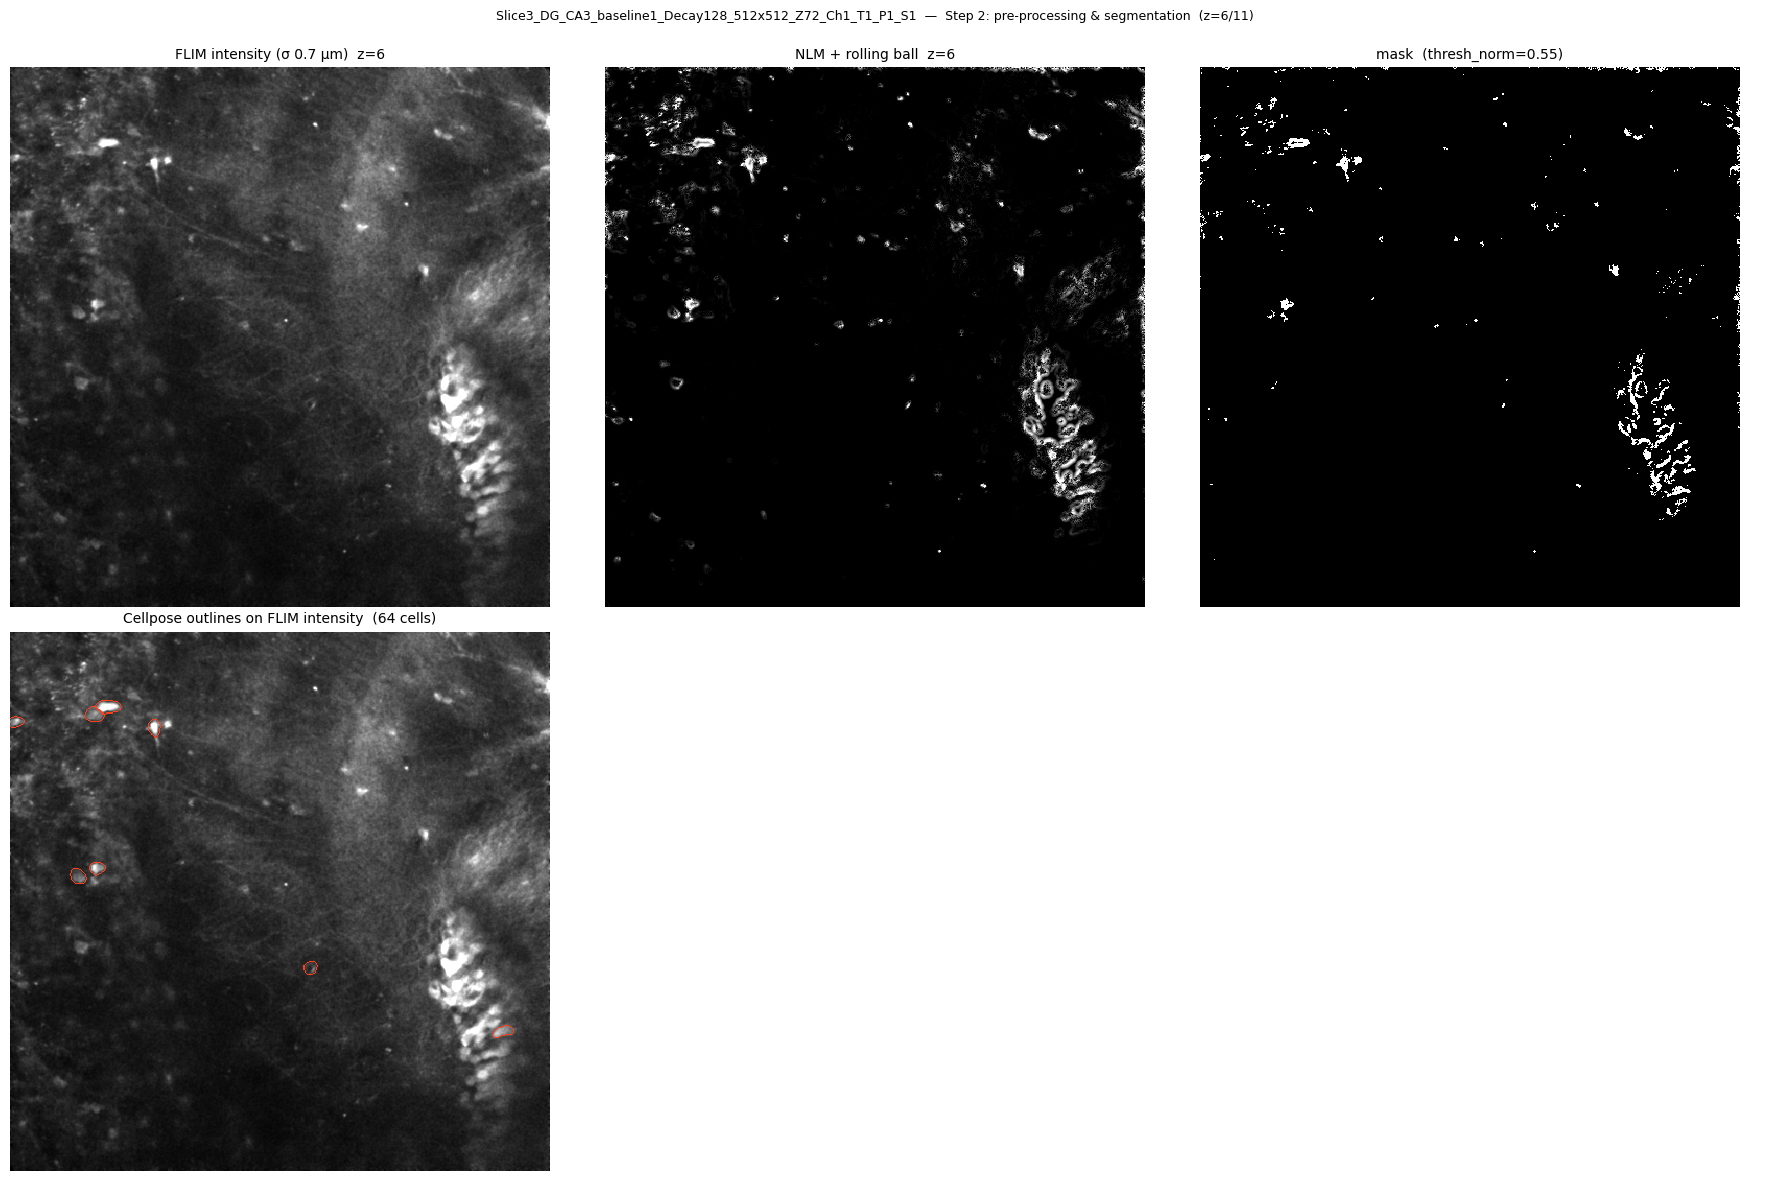

In [69]:
# ── cell source ───────────────────────────────────────────────────────────────
use_subject_reference = False   # True: cells = the subject's curated reference labels (Step 2b); Cellpose skipped

# ── Cellpose (sizes in µm; mask pre-processing parameters are set in Step 1) ───
seg_source          = 'auto'       # 'auto' = Olympus channel (Step 0e) if present, else 'flim' (photon-sum reference)
cp_mode             = '2d_stitch'  # '2d_stitch' (per plane, linked across z) or '3d' (very slow at small diameters)
cp_diameter_um      = 10.0         # expected object diameter in xy
cp_cellprob_thresh  = -3.0         # lower -> more / larger objects (Cellpose default 0)
cp_flow_threshold   = 0.0          # largest flow error a mask may have: 0 = check off, higher = more lenient (default 0.4)
cp_stitch_threshold = 0.25         # 2D: masks on neighbouring planes are one cell when IoU >= this (best match only)
cp_min_volume_um3   = None         # None = sphere of half the diameter
cp_model_path       = None         # fine-tuned model (Cellpose_FineTune.ipynb); None = generic cpsam
cp_gpu              = True
_rerun_cp           = False        # True: re-run Cellpose even if masks with these settings exist
# before 2026-11-20: d 8 µm, cellprob -1.5, flow 0.4, on the mean of per-timepoint-normalised intensities

# ── quality filter of the Cellpose cells ──────────────────────────────────────
cell_min_contrast = 1.25    # dropped below: cell mean / median of a ring around it (segmentation input)
cell_ring_um      = 3.0     # ring width (µm, in-plane; other cells and unrecorded voxels left out)
cell_min_fov      = 0.9     # a timepoint counts when this fraction of the cell was recorded (Step 17: tc_min_fov)
cell_min_photons  = 500     # photons per cell and timepoint (as min_photons of Steps 14 / 17)
cell_min_tp       = 'all'   # timepoints meeting both for `cells_time_ok` (int or 'all'): a flag, cells are kept

from skimage.segmentation import find_boundaries
from scipy.ndimage import uniform_filter as _ndi_uniform
_voxel_sp = (z_step_um, xy_pixel_um, xy_pixel_um)
if cp_model_path:   # the model was trained at one scale: use its diameter
    _ft_meta = json.load(open(cp_model_path + '.json'))
    if _ft_meta['diameter_um'] != cp_diameter_um:
        print(f'cp_diameter_um {cp_diameter_um} -> {_ft_meta["diameter_um"]} µm (training scale of '
              f'{os.path.basename(cp_model_path)})')
        cp_diameter_um = _ft_meta['diameter_um']
if seg_source == 'auto':
    seg_source = 'olympus' if stitch_oir else 'flim'
if seg_source == 'olympus' and not stitch_oir:
    raise RuntimeError("seg_source='olympus' but Step 0e produced no Olympus channel")
_seg_name = f'Olympus {oir_ch["name"]} ({oir_ch["filter"]})' if seg_source == 'olympus' else 'FLIM photon-sum reference'

_filt_path = os.path.join(newFolder, f'{FName}_sumTCSPC_3Dfilt_norm.tif')
_pre_json  = _filt_path.replace('.tif', '.json')                          # settings of vol_norm_3d
_mask_path = os.path.join(newFolder, f'{FName}_mask3d.tif')               # written by Step 3
_cp_all    = os.path.join(newFolder, f'{FName}_cellpose_masks_all.tif')   # Cellpose output (before the filter)
_cp_path   = os.path.join(newFolder, f'{FName}_cellpose_masks.tif')       # kept cells = cp_masks
_cp_json   = _cp_path.replace('.tif', '.json')                            # Cellpose settings of _cp_all
_cp_qc_csv = os.path.join(newFolder, f'{FName}_cellpose_qc.csv')
_newer = lambda p, *srcs: os.path.exists(p) and all(os.path.getmtime(p) > os.path.getmtime(s) for s in srcs)

# ── volumes: photon-sum reference of Step 0d (vol_sum3d keeps its name for the later steps) ──
vol_sum3d = seg_ref
vol_valid = seg_ntp > 0                       # voxels recorded by at least one timepoint x tile
vol_seg3d = tifffile.imread(stitch_oir).astype(np.float32) if seg_source == 'olympus' else vol_sum3d
if vol_seg3d.shape != vol_sum3d.shape:
    raise ValueError(f'{_seg_name} volume {vol_seg3d.shape} != FLIM reference {vol_sum3d.shape}')
print(f'Segmentation input: {_seg_name}')

# ── mask pre-processing -> vol_norm_3d, intensity mask (Step 3 adds the cells -> mask3d) ──
_pre_settings = dict(source=os.path.basename(seg_ref_path), smooth_um=mask_smooth_um, nlm=nlm_mode, nlm_hfac=nlm_hfac,
                     patch_size=nlm_patch_size, patch_dist=nlm_patch_dist, fast=nlm_fast, bg=bg_mode, bg_um=bg_um,
                     bg_height=bg_height, xy_um=xy_pixel_um)
if (_newer(_filt_path, seg_ref_path) and os.path.exists(_pre_json)
        and json.load(open(_pre_json)) == _pre_settings):
    vol_norm_3d = tifffile.imread(_filt_path).astype(np.float32)
    print(f'Reloaded  vol_norm_3d  {vol_norm_3d.shape}  <- {os.path.basename(_filt_path)}')
else:
    _t0 = datetime.now()
    vol_norm_3d = md.preprocess_volume(vol_sum3d, nlm=nlm_mode, nlm_hfac=nlm_hfac, patch_size=nlm_patch_size,
                                       patch_distance=nlm_patch_dist, fast_mode=nlm_fast, bg=bg_mode,
                                       rb_radius=bg_um / xy_pixel_um, bg_height=bg_height,
                                       smooth_px=(0, mask_smooth_um / xy_pixel_um, mask_smooth_um / xy_pixel_um),
                                       valid=vol_valid)
    tifffile.imwrite(_filt_path, vol_norm_3d)
    with open(_pre_json, 'w') as _f:
        json.dump(_pre_settings, _f, indent=1)
    print(f'Saved: {_filt_path}  ({(datetime.now() - _t0).total_seconds():.0f} s)')
mask_int = vol_norm_3d >= thresh_norm
print(f'Intensity mask: {mask_int.sum():,} voxels  ({100 * mask_int[vol_valid].mean():.1f}% of the recorded volume)  '
      f'thresh_norm={thresh_norm}')

# ── Cellpose + quality filter (skipped when the cells come from the subject reference) ──
cp_masks, n_cells = None, 0
cells_time_ok = None     # cell ids usable at every timepoint (Step 17 summary); None = not judged (Step 2b cells)
df_cellqc     = None
cell_tag   = ''          # file-name tag of the Steps 14-16 outputs (Step 2b sets it for reference cells)
cells_path = _cp_path    # label file the Steps 14-17 caches must be newer than
if use_subject_reference:
    print('Cellpose skipped: cells come from the subject reference (Step 2b).')
else:
    _cp_settings = dict(source=seg_source, channel=oir_ch['id'] if seg_source == 'olympus' else None,
                        input='photonsum' if seg_source == 'flim' else 'olympus', spacing=list(_voxel_sp),
                        mode=cp_mode, diameter_um=cp_diameter_um, cellprob_threshold=cp_cellprob_thresh,
                        flow_threshold=cp_flow_threshold, stitch_threshold=cp_stitch_threshold,
                        min_volume_um3=cp_min_volume_um3,
                        model=[cp_model_path, os.path.getmtime(cp_model_path)] if cp_model_path else None)
    _old = json.load(open(_cp_json)) if os.path.exists(_cp_json) else None
    _seg_src = stitch_oir if seg_source == 'olympus' else seg_ref_path
    if _newer(_cp_all, _seg_src) and _old == _cp_settings and not _rerun_cp:
        _cp_raw = tifffile.imread(_cp_all)
        print(f'Reloaded  Cellpose masks  {_cp_raw.shape}  <- {os.path.basename(_cp_all)}')
    else:
        if os.path.exists(_cp_path) and _old is None:   # masks from before the settings file: keep them
            os.replace(_cp_path, _cp_path.replace('.tif', '_old.tif'))
            print(f'Kept previous masks as {os.path.basename(_cp_path).replace(".tif", "_old.tif")}')
        print(f'Running Cellpose ({cp_mode}, {os.path.basename(cp_model_path) if cp_model_path else "cpsam"}) on '
              f'{_seg_name}  d={cp_diameter_um} µm  cellprob={cp_cellprob_thresh}  flow={cp_flow_threshold}  '
              f'gpu={cp_gpu}...', flush=True)
        _t0 = datetime.now()
        _cp_raw = md.segment_cellpose(md.seg_input(vol_seg3d, _voxel_sp), _voxel_sp, cp_diameter_um, mode=cp_mode,
                                      cellprob_threshold=cp_cellprob_thresh, flow_threshold=cp_flow_threshold,
                                      stitch_threshold=cp_stitch_threshold, min_volume_um3=cp_min_volume_um3,
                                      gpu=cp_gpu, model_path=cp_model_path)
        tifffile.imwrite(_cp_all, _cp_raw)
        with open(_cp_json, 'w') as _f:
            json.dump(_cp_settings, _f, indent=1)
        print(f'Done in {(datetime.now() - _t0).total_seconds():.0f} s.  Saved: {_cp_all}')
    _st = md.mask_stats(_cp_raw, _voxel_sp)
    print(f'Cellpose: {_st["n"]} cells  |  median xy diameter {_st["diam_xy_um"]:.1f} µm  |  '
          f'median z extent {_st["z_extent_um"]:.1f} µm')

    # ── quality filter: drop cells no brighter than their surround, flag cells usable at every timepoint ──
    df_cellqc, _qc_arr = md.cell_quality(_cp_raw, vol_seg3d, tile_int_t, canvas_pos, xy_pixel_um, recorded=vol_valid,
                                         ring_um=cell_ring_um, min_fov=cell_min_fov, min_photons=cell_min_photons)
    _need = n_timepoints if cell_min_tp == 'all' else int(cell_min_tp)
    df_cellqc['keep']    = ~(df_cellqc['contrast'] < cell_min_contrast)   # NaN (no ring: surrounded by cells) kept
    df_cellqc['time_ok'] = df_cellqc['tp_usable'] >= _need
    _keep = df_cellqc.loc[df_cellqc['keep'], 'cell_id'].to_numpy()
    _lut  = np.zeros(int(_cp_raw.max()) + 1, np.uint16 if _keep.size < 65535 else np.uint32)
    _lut[_keep] = np.arange(1, _keep.size + 1)
    cp_masks = _lut[_cp_raw]
    df_cellqc.insert(0, 'cp_id', df_cellqc.pop('cell_id'))
    df_cellqc.insert(0, 'cell_id', _lut[df_cellqc['cp_id'].to_numpy()])  # id in cp_masks, 0 = dropped
    df_cellqc.to_csv(_cp_qc_csv, index=False)
    cells_time_ok = df_cellqc.loc[df_cellqc['keep'] & df_cellqc['time_ok'], 'cell_id'].to_numpy()
    if not (os.path.exists(_cp_path) and np.array_equal(tifffile.imread(_cp_path), cp_masks)):
        tifffile.imwrite(_cp_path, cp_masks)   # only when it changes: its date invalidates the Steps 14-17 caches
        print(f'Saved: {_cp_path}')
    n_cells = int(cp_masks.max())
    print(f'Quality filter: {n_cells} kept, {int((~df_cellqc["keep"]).sum())} dropped (contrast < {cell_min_contrast:g})'
          f'  -> cp_masks, {os.path.basename(_cp_qc_csv)}')
    print(f'  usable at >= {_need}/{n_timepoints} timepoints (>= {cell_min_fov:.0%} recorded, >= {cell_min_photons} '
          f'photons): {cells_time_ok.size} of the kept cells  -> Step 17 summary')

# ── QC figure: middle plane, outlines by verdict over the intensity mask ──────
_zq  = mid_idx
_im  = md.seg_input(vol_seg3d[_zq:_zq + 1], _voxel_sp, sigma_um=(0, 0.7, 0.7))[0]
_sel = _im[vol_valid[_zq]] if vol_valid[_zq].any() else _im.ravel()
_lo, _hi = np.percentile(_sel, 1), np.percentile(_sel, 99.7)
_rgb = np.dstack([np.clip((_im - _lo) / max(_hi - _lo, 1e-12), 0, 1)] * 3)
_rgb[mask_int[_zq]] = 0.6 * _rgb[mask_int[_zq]] + 0.4 * np.array([0.1, 0.8, 0.9])
if df_cellqc is not None:          # Cellpose cells: red kept, magenta kept but not usable at every timepoint, yellow dropped
    _cat = np.zeros(int(_cp_raw.max()) + 1, np.uint8)
    _cat[df_cellqc['cp_id'].to_numpy()] = np.select([~df_cellqc['keep'].to_numpy(), df_cellqc['time_ok'].to_numpy()],
                                                    [3, 1], 2)
    _b = find_boundaries(_cp_raw[_zq], mode='inner')
    for _k, _c in {1: (1.0, 0.25, 0.1), 2: (1.0, 0.2, 1.0), 3: (1.0, 0.9, 0.0)}.items():
        _rgb[_b & (_cat[_cp_raw[_zq]] == _k)] = _c
_cz = min(int(round(200 / xy_pixel_um)), *_rgb.shape[:2])       # 200 µm zoom where the kept cells are densest
_dens = _ndi_uniform((cp_masks[_zq] > 0).astype(float), _cz) if cp_masks is not None else np.zeros(_rgb.shape[:2])
_cy, _cx = np.unravel_index(np.argmax(_dens), _dens.shape) if _dens.any() else (_rgb.shape[0] // 2, _rgb.shape[1] // 2)
_y0 = int(np.clip(_cy - _cz // 2, 0, _rgb.shape[0] - _cz)); _x0 = int(np.clip(_cx - _cz // 2, 0, _rgb.shape[1] - _cz))

_npan = 4 if df_cellqc is not None else 2
fig, axs = plt.subplots(1, _npan, figsize=(6.2 * _npan, 6.4),
                        gridspec_kw=dict(width_ratios=[1, 1, 0.8, 0.8][:_npan]))
axs[0].imshow(_rgb, interpolation='nearest')
axs[0].add_patch(plt.Rectangle((_x0 - 0.5, _y0 - 0.5), _cz, _cz, fill=False, ec='w', lw=1, ls='--'))
axs[0].set_title(f'{_seg_name}  z={_zq}  (cyan: intensity mask)', fontsize=9)
axs[1].imshow(_rgb[_y0:_y0 + _cz, _x0:_x0 + _cz], interpolation='nearest')
axs[1].set_title('red: kept  ·  magenta: kept, not usable at every timepoint  ·  yellow: dropped'
                 if df_cellqc is not None else 'intensity mask (cells from the subject reference: Step 2b)', fontsize=9)
for _a in axs[:2]:
    _a.axis('off')
if df_cellqc is not None:
    axs[2].hist(np.clip(df_cellqc['contrast'].dropna(), 0, 4), bins=60, color='0.5')
    axs[2].axvline(cell_min_contrast, color='r', ls='--')
    axs[2].set(xlabel='cell mean / ring median (clipped at 4)', ylabel='Cellpose cells')
    axs[2].set_title(f'contrast: {int((~df_cellqc["keep"]).sum())} of {len(df_cellqc)} below '
                     f'{cell_min_contrast:g}', fontsize=9)
    _ph = np.where(_qc_arr['fov'] >= cell_min_fov, _qc_arr['photons'], np.nan)[
        :, df_cellqc.loc[df_cellqc['keep'], 'cp_id'].to_numpy() - 1]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        _q = np.nanpercentile(_ph, [10, 50, 90], axis=1)
    _x = np.arange(_ph.shape[0])
    axs[3].fill_between(_x, _q[0], _q[2], color='C0', alpha=0.25, label='10-90 %')
    axs[3].plot(_x, _q[1], 'o-', color='C0', label='median')
    axs[3].axhline(cell_min_photons, color='r', ls='--', label=f'{cell_min_photons}')
    axs[3].set(yscale='log', xlabel='timepoint', ylabel='photons per cell', xticks=_x)
    axs[3].set_title(f'kept cells >= {cell_min_fov:.0%} recorded', fontsize=9); axs[3].legend(fontsize=8)
plt.suptitle(f'{FName}  —  Step 2: segmentation & cell quality  ({n_cells} cells)', fontsize=9)
plt.tight_layout()
plt.show()


## Step 2b: cells from the subject reference (multi-day tracking)
Runs only with `use_subject_reference = True` (Step 2). Needs the subject's curated `reference_labels.tif`
(`MultiDay_Reference.ipynb`).
1. **Register** this session's segmentation volume (Olympus red when present, else the FLIM intensity; fixed) to the
   reference (moving), in µm: MIP phase correlation
   + rotation sweep + depth search, then SimpleITK rigid (optionally a bounded B-spline) → `registration/*.h5`.
2. **Transfer labels**: reference labels → this session's grid (nearest neighbour; the TCSPC data are never
   resampled), then a per-cell local shift search (±3 µm) → `registration/<FName>_ref<id>_labels.tif`.
3. **QC per cell** (`<FName>_ref<id>_cell_qc.csv`): `ok`, `partial` (cut by the FOV or coverage), `low_match`
   (local NCC < 0.3), `outside`. Cells are flagged, not dropped; `cell_id` = the global reference ID.
4. The session is added to `<subject>/sessions.json`; Steps 14–16 then write `<FName>_ref<id>_*.csv`.

In [ ]:
# ── Step 2b: subject reference -> session labels ──────────────────────────────
subject_id        = vista_info['base'].split('_')[1]   # 'XYZT1_336_...' -> '336'
subject_root      = r'D:\Peredox_FLIM\subjects'
reg_stages        = ('rigid',)          # add 'bspline' if the overlay shows residual local warping
refine_shift_um   = (3.0, 3.0, 3.0)     # per-cell local search (z, y, x) after the label transfer
rerun_subject_reg = False               # True: redo registration + label transfer

if not use_subject_reference:
    print('Step 2b skipped (use_subject_reference = False): cells from Cellpose (Step 2).')
else:
    importlib.reload(md)
    subject_dir = os.path.join(subject_root, subject_id)
    _ref = md.load_reference(subject_dir)
    if _ref['labels'] is None:
        raise RuntimeError(f'No curated reference_labels.tif in {subject_dir} — run MultiDay_Reference.ipynb first.')
    cell_tag   = f'_ref{subject_id}'
    _reg_dir   = os.path.join(newFolder, 'registration')
    os.makedirs(_reg_dir, exist_ok=True)
    _tf_path   = os.path.join(_reg_dir, f'{FName}_to_ref{subject_id}.h5')
    cells_path = os.path.join(_reg_dir, f'{FName}{cell_tag}_labels.tif')
    _qc_path   = os.path.join(newFolder, f'{FName}{cell_tag}_cell_qc.csv')
    _ses_sp    = (z_step_um, xy_pixel_um, xy_pixel_um)
    _ses_cov   = tifffile.imread(stitch['cov_path'])
    _ses_p     = md.reg_prep(vol_seg3d, _ses_sp)      # Olympus red when present (Step 2), else the FLIM intensity
    _ref_p     = md.reg_prep(_ref['vol'], _ref['spacing'])

    # ── registration: session (fixed) -> reference (moving) ───────────────────
    if os.path.exists(_tf_path) and not rerun_subject_reg:
        T_ref, reg_summary = md.load_transform(_tf_path)
        print(f'Reloaded transform <- {os.path.basename(_tf_path)}')
    else:
        _reg = md.register_session(_ref_p, _ref['spacing'], _ses_p, _ses_sp, mov_mask=_ses_cov > 0,
                                   stages=reg_stages)
        md.save_transform(_tf_path, _reg, session=FName, reference=_ref['meta']['source'])
        T_ref, reg_summary = md.load_transform(_tf_path)
        print(f'Saved transform -> {_tf_path}')
    print(f'NCC per stage: { {k: round(v, 3) for k, v in reg_summary["ncc"].items()} }')

    # ── label transfer + per-cell refinement + QC ─────────────────────────────
    _ref_w = md.warp_to_session(_ref_p, _ref['spacing'], T_ref, vol_sum3d.shape, _ses_sp)
    _newer = lambda p, *srcs: os.path.exists(p) and all(os.path.getmtime(p) > os.path.getmtime(s) for s in srcs)
    if (not rerun_subject_reg and _newer(cells_path, _tf_path, md.subject_paths(subject_dir)['ref_labels'])
            and os.path.exists(_qc_path)):
        cp_masks   = tifffile.imread(cells_path)
        df_cell_qc = pd.read_csv(_qc_path)
        print(f'Reloaded session labels <- {os.path.basename(cells_path)}')
    else:
        _lab0 = md.warp_to_session(_ref['labels'], _ref['spacing'], T_ref, vol_sum3d.shape, _ses_sp, labels=True)
        cp_masks, _df_ref = md.refine_cells(_lab0, _ses_p, _ref_w, _ses_sp, max_shift_um=refine_shift_um)
        df_cell_qc = md.cell_qc(_ref['labels'], _ref['spacing'], cp_masks, _ses_sp, coverage=_ses_cov,
                                refine_df=_df_ref)
        tifffile.imwrite(cells_path, cp_masks.astype(np.uint16), compression='zlib')
        df_cell_qc.to_csv(_qc_path, index=False)
        print(f'Saved session labels -> {cells_path}')
    n_cells = int(_ref['labels'].max())     # global IDs: rows 1 .. max reference ID
    md.update_sessions(subject_dir, session=FName, date=md.session_date(raw_path), raw_path=raw_path,
                       analysis_dir=newFolder, cell_tag=cell_tag, transform=_tf_path, labels=cells_path,
                       qc=_qc_path)
    print(f'Reference cells: {len(df_cell_qc)}  |  flags: {df_cell_qc.flag.value_counts().to_dict()}')

    md.plot_registration_qc(_ses_p, _ref_w, _ses_sp, mask=_ses_cov > 0, labels=cp_masks, z=mid_idx,
                            title=f'{FName}  ->  reference {subject_id}')
    plt.show()

## Step 3: Mask preparation (middle plane)
`mask3d` = intensity mask of Step 2 (`vol_norm_3d >= thresh_norm`) ∪ the cells (Step 2 or 2b): the pixel maps of
Steps 3–13 and the per-cell pixel statistics of Step 16 cover whole cells (a threshold alone keeps only the bright
part of dim cells, and cpGFP brightness follows NADH binding). Saved as `*_mask3d.tif`. Middle plane → `maskTCSPC`
(float, 0/1) and `maskFilt_bool` (boolean).

In [ ]:
# ── pixel mask of Steps 3-13: intensity mask (Step 2) ∪ cells (Step 2 / 2b) ────
mask3d = (mask_int | (cp_masks > 0)) if cp_masks is not None else mask_int.copy()
tifffile.imwrite(_mask_path, mask3d.astype(np.uint8))
print(f'mask3d: {100 * mask3d[vol_valid].mean():.1f}% of the recorded volume  (intensity mask '
      f'{100 * mask_int[vol_valid].mean():.1f}%'
      + (f', cells {100 * (cp_masks > 0)[vol_valid].mean():.1f}%)' if cp_masks is not None else ')'))

# ── middle plane ──────────────────────────────────────────────────────────────
maskTCSPC     = mask3d[mid_idx].astype(float)
maskFilt_bool = mask3d[mid_idx]

# ── save middle-plane intensity maps ─────────────────────────────────────────
imwrite(os.path.join(newFolder, f'{FName}_sumTCSPC.tif'), sumTCSPC.astype(np.float32))
imwrite(os.path.join(newFolder, f'{FName}_sumTCSPC_filt_norm.tif'),
        vol_norm_3d[mid_idx].astype(np.float32))

print(f'maskTCSPC valid pixels: {maskFilt_bool.sum():.0f}  (thresh_norm={thresh_norm})')

## Step 4: IRF preprocessing
1. Sum over spatial dims to get a 1-D IRF trace.
2. Subtract median of last 25 bins (background) and clip negatives.

In [ ]:
IRF2 = IRF.sum(axis=tuple(range(IRF.ndim - 1))) if IRF.ndim > 1 else IRF.copy()
IRF2 = IRF2.ravel().astype(float)
Ix   = len(IRF2)

# IRF2 = np.roll(IRF2, 2)           # 2-bin right-shift -- legacy from old instrument, not needed
IRF2 = IRF2 - np.median(IRF2[-25:]) # subtract background (median of last 25 bins)
IRF2 = IRF2 + np.abs(IRF2.min())    # clip negatives to zero

print(f'IRF bins (Ix): {Ix}')
print(f'IRF peak at bin {np.argmax(IRF2)},  max = {IRF2.max():.1f}')


## Step 5: Peak realignment
Circularly shifts `DataTCSPC` and `IRF2` so both peaks land at 8 % of `nbin` (the same target frame). This single global alignment replaces the old per-session manual shift and ensures `F - H` is unbiased.

In [ ]:
## Step 4b: Peak realignment
# Circularly shifts DataTCSPC and IRF2 so both peaks land at 8% of nbin.

# ── bin count check ───────────────────────────────────────────────────────────
nbin_data = DataTCSPC.shape[2]
if nbin_data != Ix:
    warnings.warn(
        f'Bin count mismatch: DataTCSPC has {nbin_data} bins, IRF has {Ix} bins. '
        'Check dim_data / dim_irf — bin alignment (code-06) may need re-enabling.',
        RuntimeWarning, stacklevel=2)
nbin = nbin_data
dt   = Tcycle / nbin
tau  = np.arange(1, nbin + 1) * dt
print(f'nbin = {nbin},  dt = {dt:.4f} ns')

# ── target frame: 8% of nbin ─────────────────────────────────────────────────
target = int(round(0.08 * nbin))
print(f'Target peak frame: {target} / {nbin}  ({100 * target / nbin:.1f}%)')

# ── pixel mask ────────────────────────────────────────────────────────────────
maskPixel    = mask3d[mid_idx]
decay_masked = DataTCSPC[maskPixel].sum(axis=0).astype(float)

# ── shift DataTCSPC so fluorescence peak → target frame ──────────────────────
peak_data  = int(np.argmax(decay_masked))
shift_data = target - peak_data
DataTCSPC  = np.roll(DataTCSPC, shift_data, axis=2)
print(f'Data  peak was frame {peak_data:3d},  shifted by {shift_data:+d}')

# ── shift IRF2 so its peak → target frame ────────────────────────────────────
peak_irf  = int(np.argmax(IRF2))
shift_irf = target - peak_irf
IRF2      = np.roll(IRF2, shift_irf)
print(f'IRF   peak was frame {peak_irf:3d},  shifted by {shift_irf:+d}')

# ── sanity-check plot ─────────────────────────────────────────────────────────
_decay_aligned = DataTCSPC[maskPixel].sum(axis=0).astype(float)
_decay_n       = _decay_aligned / _decay_aligned.max()
_irf_n         = IRF2 / IRF2.max()

fig_align, ax_align = plt.subplots(figsize=(7, 4))
ax_align.semilogy(tau, _irf_n, '--k', linewidth=0.8, label='IRF')
ax_align.semilogy(tau, _decay_n, color='steelblue', linewidth=1.2,
                  label=f'Data  ({maskPixel.sum()} px)')
ax_align.axvline(tau[target], color='orange', linewidth=1, linestyle=':',
                 label=f'target  frame {target}')
ax_align.set_xlabel('time / ns')
ax_align.set_ylabel('intensity (norm.)')
ax_align.set_title(f'After realignment  [{FName}]' + (f'\n{meta_str}' if meta_str else ''),
                   fontsize=10)
ax_align.set_xlim(0, Tcycle)
ax_align.set_ylim(5e-3, 1.3)
ax_align.legend()
fig_align.tight_layout()
plt.show()

## Step 6: Masked decay & time axis
Builds the time axis `tau` and computes the spatially-masked average decay `tmp1` used for alignment and fitting.

In [ ]:
# DataTCSPC = np.roll(DataTCSPC, 2, axis=2)   # 2-bin shift -- not needed for new instrument

dt  = Tcycle / nbin
tau = np.arange(1, nbin + 1) * dt               # time axis (ns)

# masked average decay (pixels >= threshold) -- consistent with maskPixel
# convert maskTCSPC to boolean for indexing, but keep original maskPixel for stats
maskTCSPCbool = maskTCSPC.astype(bool)
tmp1 = DataTCSPC[maskPixel].sum(axis=0).astype(float)

tmp = tmp1 / tmp1.max()
irf = IRF2 / IRF2.max()

print(f'dt = {dt:.4f} ns,  tau: {tau[0]:.3f} to {tau[-1]:.3f} ns')
print(f'Total photons in masked area: {tmp1.sum():.0f}  ({maskPixel.sum()} pixels)')


## Step 7: Apply count-threshold mask
Zeroes out pixels below `threshold` photon counts before the lifetime computation.

In [ ]:
bc = (slice(None), slice(None)) + (np.newaxis,) * (DataTCSPC.ndim - 2)
DataTCSPC = DataTCSPC * maskTCSPC[bc]
print(f'Pixels zeroed out: {(maskTCSPC == 0).sum():.0f}')

## Step 8: Mean-arrival-time lifetime (tav)
**Key equations:**
- `H = sum(tau * IRF) / sum(IRF)` — mean arrival time of the IRF (instrument offset)
- `F[x,y] = sum(tau * data[x,y]) / sum(data[x,y])` — mean photon arrival time per pixel
- `tav = F - H` — fluorescence lifetime estimate per pixel (ns)

In [ ]:
DataTCSPC = DataTCSPC.astype(float)
if DataTCSPC.ndim == 3:
    DataTCSPC = DataTCSPC[:, :, :, np.newaxis]

nx, ny, nbin, nch = DataTCSPC.shape
T = tau[np.newaxis, np.newaxis, :, np.newaxis]

H = float(np.dot(tau, IRF2) / IRF2.sum())

F = (T * DataTCSPC).sum(axis=2) / DataTCSPC.sum(axis=2)
F = np.nan_to_num(F)

tag = DataTCSPC.sum(axis=2).squeeze()
tav = (F - H).squeeze()
tav = np.clip(tav, 0, None)

print(f'H (IRF mean arrival time): {H:.4f} ns')
valid_tav = tav[maskTCSPCbool & (tav > 0)]
if valid_tav.size > 0:
    print(f'tav stats (masked) -- min: {valid_tav.min():.3f} ns,  '
          f'mean: {valid_tav.mean():.3f} ns,  max: {valid_tav.max():.3f} ns')

_tav_disp = tav.copy().astype(float)
_tav_disp[~maskTCSPCbool] = np.nan
_pos = _tav_disp[np.isfinite(_tav_disp) & (_tav_disp > 0)]
_vmin = float(np.percentile(_pos,  1)) if _pos.size else 0.0
_vmax = float(np.percentile(_pos, 90)) if _pos.size else 1.0

fig, ax = plt.subplots(figsize=(6, 5), facecolor='black')
ax.set_facecolor('black')
im = ax.imshow(_tav_disp, cmap='gnuplot2', aspect='equal', origin='upper',
               vmin=_vmin, vmax=_vmax)
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('tav / ns', color='white')
cbar.ax.yaxis.set_tick_params(color='white')
plt.setp(cbar.ax.yaxis.get_ticklabels(), color='white')
cbar.outline.set_visible(False)
ax.set_title(f'Mean arrival-time lifetime  [{FName}]' + (f'\n{meta_str}' if meta_str else ''),
             fontsize=10, color='white')
ax.set_xlabel('x / px', color='white')
ax.set_ylabel('y / px', color='white')
ax.tick_params(colors='white')
for spine in ax.spines.values():
    spine.set_edgecolor('white')
plt.tight_layout()
plt.show()

## Step 9: Bilateral filter on tav
Edge-preserving smooth of the lifetime map. `sigma_spatial` controls neighbourhood size; `sigma_lifetime` (ns) controls how much lifetime difference is tolerated — sharp compartment boundaries are preserved while shot-noise within a compartment is averaged. Overwrites `tav` in place; skip to keep the raw map.

In [ ]:
# ── parameters ────────────────────────────────────────────────────────────────
sigma_spatial   = 4.0   # spatial Gaussian σ (pixels)   — larger = more smoothing
sigma_lifetime  = 0.4   # range σ (ns) — lifetimes within this are averaged;
                        #   increase to smooth across compartments, decrease to sharpen edges

# calc std of tav for later use in range-based filtering (optional)
tav_std = np.nanstd(tav[maskTCSPCbool & (tav > 0)])
print(f'tav std (masked, positive pixels): {tav_std:.3f} ns')
sigma_lifetime = max(sigma_lifetime, 0.5 * tav_std)
print(f'Using σ_lifetime = {sigma_lifetime:.3f} ns for bilateral filter')

# ── apply ─────────────────────────────────────────────────────────────────────
# Mask invalid pixels as NaN so they are excluded from their neighbours' averages.
_tav_in = tav.copy().astype(float)
_tav_in[~maskTCSPCbool] = np.nan

_tav_filled = np.where(np.isfinite(_tav_in), _tav_in, float(np.nanmean(_tav_in)))
_tav_filt   = denoise_bilateral(_tav_filled, sigma_color=sigma_lifetime,
                                sigma_spatial=sigma_spatial, channel_axis=None)
_tav_filt[~maskTCSPCbool] = np.nan

# ── percentile range over positive pixels only (zeros are clipped negatives) ──
_pos = _tav_in[np.isfinite(_tav_in) & (_tav_in > 0)]
_vmin = float(np.percentile(_pos,  20)) if _pos.size else 0.0
_vmax = float(np.percentile(_pos, 80)) if _pos.size else 1.0

# ── side-by-side comparison ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5), facecolor='black')
for ax in axes:
    ax.set_facecolor('black')

axes[0].imshow(_tav_in,   cmap='gnuplot2', aspect='equal', origin='upper', vmin=_vmin, vmax=_vmax)
axes[0].set_title('tav  (raw)', fontsize=11, color='white')
im = axes[1].imshow(_tav_filt, cmap='gnuplot2', aspect='equal', origin='upper', vmin=_vmin, vmax=_vmax)
axes[1].set_title(f'tav  (bilateral  σ_spatial={sigma_spatial} px, σ_range={sigma_lifetime} ns)',
                  fontsize=11, color='white')

cbar = plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
cbar.set_label('tav / ns', color='white')
cbar.ax.yaxis.set_tick_params(color='white')
plt.setp(cbar.ax.yaxis.get_ticklabels(), color='white')
cbar.outline.set_visible(False)

for ax in axes:
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('white')

_sup = FName + (f'  —  {meta_str}' if meta_str else '')
plt.suptitle(_sup, fontsize=9, y=1.01, color='white')
plt.tight_layout()
plt.show()

# overwrite tav so downstream cells (FLIM image, metrics) use the filtered map
tav = _tav_filt
print(f'tav updated  (bilateral filtered).  '
      f'Mean: {np.nanmean(tav):.3f} ns,  std: {np.nanstd(tav):.3f} ns')

## Step 10: False-colour FLIM image
Auto-determines lifetime display range with `uplowthresh` (if `limits` is NaN), then calls `FastFLIM_mod_AT0` to generate and display the false-colour image.

In [ ]:
saveLTimg = os.path.join(newFolder, FName)
# limits    = np.asarray(limits, dtype=float) # only needed if run on loop (get the first limits value, then reuse for consistent scaling across images)
limits    = np.array([np.nan, np.nan])
if np.all(np.isnan(limits)):
    ind = tag < threshold
    if not np.any(~ind):
        ind = tag < 1
    tim_auto = tav.copy()
    tim_auto[ind] = 0
    hi1, lo1 = uplowthresh(tim_auto, 0.95, 0.05)
    limits = np.array([lo1, hi1])
    print(f'Auto limits: [{limits[0]:.3f}, {limits[1]:.3f}] ns')

LTImg, Bar = FastFLIM_mod_AT0(saveLTimg, tag, tav, threshold, limits)

## Step 11: Phasor — z-projected, IRF corrected
Combines the full z-stack photon budget for a denser, lower-noise phasor:
1. **Z-projection** — accumulates all z-plane TCSPC arrays into one `(ny, nx, nbin)` image using the same `shift_data` alignment as the rest of the pipeline.
2. **G/S computation** — DFT at the laser repetition frequency with optional `szBin` spatial binning; no uncorrected phasor plot is shown.
3. **IRF reference correction** — maps the IRF phasor to `(G=1, S=0)`, applies the same modulation/phase factors to the sample. Results in `G_corr` / `S_corr`; corrected plot saved as `*_Phas_corr.png`.

`G_ref` / `S_ref` produced here are also consumed by the per-cell phasor cell (Step 15).

In [ ]:
freq_mhz = 1000.0 / Tcycle
tau_p    = (np.arange(1, nbin + 1) - 0.5) * dt

try:
    # ── IRF reference phasor ──────────────────────────────────────────────────
    _ph_irf = np.dot(tau_p, IRF2) / IRF2.sum()
    _T_irf  = 2.0 * np.pi * (tau_p - _ph_irf) / Tcycle
    _w_irf  = IRF2 / IRF2.sum()
    G_ref   = np.array([[float(np.dot(np.cos(_T_irf), _w_irf))]])
    S_ref   = np.array([[float(np.dot(np.sin(_T_irf), _w_irf))]])
    print(f'IRF phasor:  G_ref = {G_ref[0,0]:.4f},  S_ref = {S_ref[0,0]:.4f}')

    # ── accumulate z-projected TCSPC (one plane at a time) ───────────────────
    print(f'Accumulating z-projected TCSPC ({n_planes} planes)...', end=' ', flush=True)
    _tcspc_proj = np.zeros((nx, ny, nbin), dtype=float)
    for _path in data_paths:
        _DataZ = _to_yxt(tifffile.imread(_path).astype(float), dim_data)
        _tcspc_proj += np.roll(_DataZ, shift_data, axis=2)
    print('done.')

    # ── compute G / S without plot (mirrors Calc_Phasor_Mat internals) ───────
    _D = _tcspc_proj.copy()
    if szBin > 1:
        _nyb = (nx // szBin) * szBin
        _nxb = (ny // szBin) * szBin
        _D   = _D[:_nyb, :_nxb, :]
        _D   = _D.reshape(_nyb // szBin, szBin, _nxb // szBin, szBin, nbin).sum(axis=(1, 3))
    _tag   = _D.sum(axis=2)
    _ph    = np.dot(tau_p, IRF2) / IRF2.sum()
    _T     = 2.0 * np.pi * (tau_p - _ph) / Tcycle
    _T3    = _T[np.newaxis, np.newaxis, :]
    _tag_s = np.where(_tag > 0, _tag, np.nan)
    G      = (np.cos(_T3) * _D).sum(axis=2) / _tag_s
    S      = (np.sin(_T3) * _D).sum(axis=2) / _tag_s
    _bad   = (_tag < threshold) | (G < 0) | (S < 0)
    G[_bad] = np.nan;  S[_bad] = np.nan
    print(f'G raw : [{np.nanmin(G):.3f}, {np.nanmax(G):.3f}]  '
          f'S raw : [{np.nanmin(S):.3f}, {np.nanmax(S):.3f}]  '
          f'({int((~_bad).sum())} valid pixels after {szBin}x{szBin} binning)')

    # ── reference correction ──────────────────────────────────────────────────
    G_corr, S_corr, tau_mod, tau_phi = phasor_ref_correction(
        G, S, G_ref, S_ref, tau_ref_ns=0.0, freq_mhz=freq_mhz)
    print(f'G corr: [{np.nanmin(G_corr):.3f}, {np.nanmax(G_corr):.3f}]  '
          f'S corr: [{np.nanmin(S_corr):.3f}, {np.nanmax(S_corr):.3f}]')
    _vp = tau_phi[np.isfinite(tau_phi)] if tau_phi is not None else np.array([])
    if _vp.size:
        print(f'tau_phi: [{_vp.min():.3f}, {_vp.max():.3f}] ns')

    # ── build corrected phasor density matrix ─────────────────────────────────
    _gv = G_corr.ravel();  _sv = S_corr.ravel()
    _ok = np.isfinite(_gv) & np.isfinite(_sv)
    _gv, _sv = _gv[_ok], _sv[_ok]

    _nbin_p = int(round(1.0 / szPhs)) + 1
    _Xi     = np.round(_gv / szPhs).astype(int)
    _Yi     = np.round(_sv / szPhs).astype(int)
    M_corr  = np.zeros((_nbin_p, _nbin_p))
    _ok2    = (_Xi >= 0) & (_Xi < _nbin_p) & (_Yi >= 0) & (_Yi < _nbin_p)
    np.add.at(M_corr, (_Yi[_ok2], _Xi[_ok2]), 1)

    # ── corrected phasor plot ─────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(6, 6))
    fig.patch.set_facecolor('white');  ax.set_facecolor('white')
    if M_corr.max() > 0:
        _vmax_p = np.percentile(M_corr[M_corr > 0], 99)
        _cmap_p = plt.cm.jet.copy();  _cmap_p.set_under('white')
        ax.imshow(np.flipud(M_corr), extent=[0, 1, 0, 1], aspect='equal',
                  cmap=_cmap_p, origin='upper', vmin=1, vmax=_vmax_p)
    _theta = np.linspace(0, np.pi, 400)
    ax.plot(0.5 + 0.5 * np.cos(_theta), 0.5 * np.sin(_theta), '-', color='black', linewidth=1.5)
    _omega = 2.0 * np.pi * freq_mhz * 1e6
    for _tau_tick in [0.5, 1, 2, 4, 8]:
        _wt  = _omega * _tau_tick * 1e-9
        _g_t = 1.0 / (1.0 + _wt ** 2);  _s_t = _wt / (1.0 + _wt ** 2)
        ax.plot(_g_t, _s_t, 'o', color='black', markersize=5, zorder=5)
        ax.annotate(f'{_tau_tick} ns', xy=(_g_t, _s_t), color='black',
                    fontsize=8, xytext=(5, 3), textcoords='offset points')
    ax.set_xlim(0, 1.0);  ax.set_ylim(0, 0.8);  ax.set_aspect('equal')
    ax.set_xlabel('G  (corrected)', fontweight='bold', fontsize=14, fontstyle='italic')
    ax.set_ylabel('S  (corrected)', fontweight='bold', fontsize=14, fontstyle='italic')
    ax.tick_params(labelsize=11)
    ax.set_title(f'Phasor — 3D z-projected, IRF corrected  |  {_ok.sum()} pts  [{FName}]'
                 + (f'\n{meta_str}' if meta_str else ''), fontsize=10)
    plt.tight_layout()
    _fig_phas = os.path.join(newFolder, FName + '_Phas_corr.png')
    plt.savefig(_fig_phas, facecolor='white', bbox_inches='tight')
    # save as svg too: 
    _fig_phas_svg = os.path.join(newFolder, FName + '_Phas_corr.svg')
    plt.savefig(_fig_phas_svg, facecolor='white', bbox_inches='tight')
    plt.show()
    print(f'Saved: {_fig_phas}')

except Exception as _e:
    import traceback;  traceback.print_exc()
    _nbin3 = int(round(1.0 / szPhs)) + 1
    M_corr = np.zeros((_nbin3, _nbin3))
    G = S = G_corr = S_corr = tau_mod = tau_phi = G_ref = S_ref = None
    print(f'Phasor failed: {_e}')

## Step 12: Lifetime summary metrics
Three independent scalar estimates derived from `tav`:
- **Tau_av** (Method 1): mean of PMT-masked pixels where `tav > H/2`
- **Tau_norm** (Method 3): mean photon arrival time in the whole signal area minus H
- **Tau_mask** (Method 4): mean tav after re-applying the PMT mask to the photon data

In [ ]:
# Method 1 -- mean tav of PMT-masked pixels where tav > H/2
Tau_1  = tav * maskPMT
valid  = Tau_1[Tau_1 > (H / 2)]
Tau_av = float(np.nanmean(valid)) if valid.size > 0 else np.nan

# Method 3 -- mean photon arrival time across signal area minus H
Tau_norm = float(np.dot(tau, tmp1) / tmp1.sum() - H)

# Method 4 -- tav mean after re-masking photon data with PMT mask
DT_masked = DataTCSPC * maskPMT[:, :, np.newaxis, np.newaxis]
F1        = np.nansum(T * DT_masked, axis=2) / np.nansum(DT_masked, axis=2)
tav2      = np.clip((F1 - H).squeeze(), 0, None)
Tau_mask  = float(np.nanmean(tav2))

print(f'Tau_av   (Method 1 -- PMT mask, tav > H/2):  {Tau_av:.4f} ns')
print(f'Tau_norm (Method 3 -- area mean - H):         {Tau_norm:.4f} ns')
print(f'Tau_mask (Method 4 -- PMT-masked tav mean):   {Tau_mask:.4f} ns')

## Step 13: Z-stack loop (all planes)
Processes **all planes** in `data_paths` through the full pipeline.
`limits` (colourmap range) are fixed from the middle plane computed in Steps 1–10 above — run those cells first.

**Outputs per plane**
| File | Content |
|------|---------|
| `*_sumTCSPC_stack.tif` | Raw photon-count maps (float32, multi-page) |
| `*_sumTCSPC_filt_norm_stack.tif` | Filtered + normalised intensity (float32, multi-page) |
| `*_mask_stack.tif` | `mask3d` planes: intensity mask ∪ cells (float32, multi-page) |
| `*_tav_raw_stack.tif` | Per-pixel mean-arrival-time lifetime before bilateral filter |
| `*_tav_filt_stack.tif` | Bilateral-filtered lifetime (NaN = masked) |
| `*_FLIM_RGB_stack.tif` | False-colour RGB volume (uint8, multi-page) |
| `*_z###_LTimg.png` | Per-plane false-colour FLIM image |
| `*_z###_decay.png` | Per-plane aligned decay plot |
| `*_FLIM_limits.csv` | Colourmap limits (lo/hi ns) from middle plane |

In [ ]:
importlib.reload(_ffm_module)
from FastFLIM_mod_AT0 import FastFLIM_mod_AT0

# ── output stack paths ─────────────────────────────────────────────────────────
def _sp(tag): return os.path.join(newFolder, f'{FName}_{tag}.tif')
stack_sum      = _sp('sumTCSPC_stack')
stack_norm     = _sp('sumTCSPC_filt_norm_stack')
stack_mask     = _sp('mask_stack')
stack_tav_raw  = _sp('tav_raw_stack')
stack_tav_filt = _sp('tav_filt_stack')
stack_rgb      = _sp('FLIM_RGB_stack')

for _p in [stack_sum, stack_norm, stack_mask, stack_tav_raw, stack_tav_filt, stack_rgb]:
    if os.path.exists(_p): os.remove(_p)

# ── save colourmap limits to CSV ──────────────────────────────────────────────
csv_path = os.path.join(newFolder, f'{FName}_FLIM_limits.csv')
with open(csv_path, 'w', newline='') as _f:
    _w = csv.writer(_f)
    _w.writerow(['lo_ns', 'hi_ns', 'source_plane'])
    _w.writerow([f'{limits[0]:.4f}', f'{limits[1]:.4f}', f'z={mid_idx}'])
print(f'Limits  {limits[0]:.4f} – {limits[1]:.4f} ns  (from z={mid_idx})  →  {csv_path}')

# ── single global shift from bulk fluorescence ────────────────────────────────
# IRF2 was independently aligned to target by cell 5622bfa1 (using its own peak).
# Data is independently aligned to the same target using the bulk fluorescence peak.
# Both arrive at the same reference bin → F - H is unbiased, regardless of when IRF was acquired.
print(f'Computing bulk decay for global shift ({n_planes} planes)...', end=' ', flush=True)
_bulk = np.zeros(nbin, dtype=float)
for _p in data_paths:
    _bulk += _to_yxt(tifffile.imread(_p).astype(float), dim_data).sum(axis=(0, 1))
print('done.')

_peak_bulk = int(np.argmax(_bulk))
shift_bulk = target - _peak_bulk
H_bulk     = float(np.dot(tau, IRF2) / IRF2.sum())   # IRF2 already at target
T_4d       = tau[np.newaxis, np.newaxis, :, np.newaxis]

print(f'Bulk peak bin {_peak_bulk}  →  shift_bulk = {shift_bulk:+d}  |  H_bulk = {H_bulk:.4f} ns')
print(f'{n_planes} planes to process\n')

# ── create output subfolders ─────────────────────────────────────────────────
_zdecay_dir  = os.path.join(newFolder, 'z_decay_plots')
_flimrgb_dir = os.path.join(newFolder, 'FLIM_RGB_planes')
os.makedirs(_zdecay_dir,  exist_ok=True)
os.makedirs(_flimrgb_dir, exist_ok=True)

# ── open all TiffWriters once — keeps planes in the same series ───────────────
_tw_sum  = tifffile.TiffWriter(stack_sum)
_tw_norm = tifffile.TiffWriter(stack_norm)
_tw_mask = tifffile.TiffWriter(stack_mask)
_tw_traw = tifffile.TiffWriter(stack_tav_raw)
_tw_tflt = tifffile.TiffWriter(stack_tav_filt)
_tw_rgb  = tifffile.TiffWriter(stack_rgb)

try:
    # ══════════════════════════════════════════════════════════════════════════
    for z, path in enumerate(data_paths):

        # ── 1. Load plane ──────────────────────────────────────────────────────
        _raw  = tifffile.imread(path).astype(float)
        DataZ = _to_yxt(_raw, dim_data)
        sumZ  = DataZ.sum(axis=2)

        # ── 2. Mask from 3D pre-processed volume ──────────────────────────────
        maskZ_bool = mask3d[z]
        maskZ      = maskZ_bool.astype(float)
        sumZ_norm  = vol_norm_3d[z]

        # ── 3. Apply single global shift (same for all planes) ────────────────
        DataZ = np.roll(DataZ, shift_bulk, axis=2)

        # ── 4. Decay plot — saved, not displayed ──────────────────────────────
        _dec_n = DataZ[maskZ_bool].sum(axis=0).astype(float) if maskZ_bool.any() else DataZ.sum(axis=(0, 1))
        _dec_n = _dec_n / _dec_n.max()
        _irf_n = IRF2 / IRF2.max()
        _fig_d, _ax_d = plt.subplots(figsize=(6, 3.5))
        _ax_d.semilogy(tau, _irf_n, '--k', lw=0.8, label='IRF')
        _ax_d.semilogy(tau, _dec_n, color='steelblue', lw=1.2, label=f'z={z:03d}')
        _ax_d.axvline(tau[target], color='orange', lw=0.8, ls=':')
        _ax_d.set_xlabel('time / ns'); _ax_d.set_ylabel('norm. intensity')
        _ax_d.set_title(f'Aligned decay  [{FName}]  z={z:03d}/{n_planes-1}', fontsize=9)
        _ax_d.set_xlim(0, Tcycle); _ax_d.set_ylim(5e-3, 1.3); _ax_d.legend(fontsize=8)
        _fig_d.tight_layout()
        _fig_d.savefig(os.path.join(_zdecay_dir, f'{FName}_z{z:03d}_decay.png'),
                       dpi=100, bbox_inches='tight')
        plt.close(_fig_d)

        # ── 5. Write intensity / mask planes ──────────────────────────────────
        _tw_sum.write(sumZ.astype(np.float32), contiguous=True)
        _tw_norm.write(sumZ_norm.astype(np.float32), contiguous=True)
        _tw_mask.write(maskZ.astype(np.float32), contiguous=True)

        # ── 6. Apply mask and compute tav ─────────────────────────────────────
        DataZ = (DataZ * maskZ[:, :, np.newaxis]).astype(float)[:, :, :, np.newaxis]
        with np.errstate(invalid='ignore', divide='ignore'):
            _F_z = np.nan_to_num((T_4d * DataZ).sum(axis=2) / DataZ.sum(axis=2))
        tav_z = np.clip((_F_z - H_bulk).squeeze(), 0, None)
        _tw_traw.write(tav_z.astype(np.float32), contiguous=True)

        # ── 7. Bilateral filter ───────────────────────────────────────────────
        _tav_in = tav_z.copy(); _tav_in[~maskZ_bool] = np.nan
        _fill   = float(np.nanmean(_tav_in)) if np.any(np.isfinite(_tav_in)) else 0.0
        tav_filt_z = denoise_bilateral(
            np.where(np.isfinite(_tav_in), _tav_in, _fill),
            sigma_color=sigma_lifetime, sigma_spatial=sigma_spatial, channel_axis=None)
        tav_filt_z[~maskZ_bool] = np.nan
        _tw_tflt.write(tav_filt_z.astype(np.float32), contiguous=True)

        # ── 8. False-colour FLIM image ────────────────────────────────────────
        _png_base = os.path.join(_flimrgb_dir, f'{FName}_z{z:03d}')
        LTImg_z, _ = FastFLIM_mod_AT0(_png_base, sumZ_norm, np.where(maskZ_bool, tav_filt_z, 0.0), 0.0, limits,
                                       show=(z == mid_idx))   # mask3d pixels (dim cell pixels too), brightness-weighted
        _tw_rgb.write((np.clip(LTImg_z, 0, 1) * 255).astype(np.uint8), photometric='rgb')

        # ── 9. Middle-plane QC visualisation ──────────────────────────────────
        if z == mid_idx:
            _pos_z = tav_filt_z[np.isfinite(tav_filt_z) & (tav_filt_z > 0)]
            _v0 = float(np.percentile(_pos_z,  1)) if _pos_z.size else 0.0
            _v1 = float(np.percentile(_pos_z, 99)) if _pos_z.size else 1.0
            _fig_m, _axes_m = plt.subplots(1, 2, figsize=(12, 5), facecolor='black')
            for _a in _axes_m: _a.set_facecolor('black')
            _axes_m[0].imshow(sumZ, cmap='inferno', aspect='equal', origin='upper')
            _axes_m[0].set_title(f'sumTCSPC  z={z}', color='white', fontsize=11)
            _im_m = _axes_m[1].imshow(tav_filt_z, cmap='jet', aspect='equal', origin='upper',
                                       vmin=_v0, vmax=_v1)
            _axes_m[1].set_title(f'tav filtered  z={z}', color='white', fontsize=11)
            _cb_m = plt.colorbar(_im_m, ax=_axes_m[1], fraction=0.046, pad=0.04)
            _cb_m.set_label('tav / ns', color='white')
            _cb_m.ax.yaxis.set_tick_params(color='white')
            plt.setp(_cb_m.ax.yaxis.get_ticklabels(), color='white')
            _cb_m.outline.set_visible(False)
            for _a in _axes_m:
                _a.tick_params(colors='white')
                for _s in _a.spines.values(): _s.set_edgecolor('white')
            plt.suptitle(f'{FName}  —  middle plane z={z}  (loop QC)', color='white', fontsize=9)
            plt.tight_layout()
            plt.show()

        print(f'  z={z:03d}/{n_planes-1}  tav={np.nanmean(tav_filt_z):.3f} ns  {os.path.basename(path)}')
    # ══════════════════════════════════════════════════════════════════════════

finally:
    for _tw in [_tw_sum, _tw_norm, _tw_mask, _tw_traw, _tw_tflt, _tw_rgb]:
        _tw.close()

print(f'\nDone.  {n_planes} planes processed.')
print(f'Output folder:  {newFolder}')

## Step 14: Per-cell 3D decay fitting
Fits a multi-exponential decay to each Cellpose cell's pooled 3D TCSPC.

**Speed-ups vs original:**
- **Single-pass I/O**: bulk decay and per-cell accumulation are done in one loop over z-planes (was two).
- **Vectorised accumulation**: one-hot matmul + `bincount` replace the inner `for cid in _cids` Python loop.
- **Parallel fitting**: `fit_decays` runs `Fit_decay` in worker processes (`fit_workers`: `None` = all cores but one, `1` = sequential); the results are identical to sequential fits.
- **Two-tier cache**:
  - `*_cell_acc.npz` — accumulated per-cell TCSPC + centroid arrays. Delete to force re-accumulation.
  - `*_per_cell_lifetimes.csv` — fitting results. Delete (keep `.npz`) to re-fit without re-accumulating.

Output names carry `cell_tag` (`''` for Cellpose cells, `_ref<subject>` for reference cells, Step 2b), and the caches are reused only when newer than the label file they were built from (`cells_path`).

`_cell_decays` dict is always reconstructed after loading/computing and is available for Step 15.

In [ ]:
import time as _time
importlib.reload(_ffm_module)
import flim_helpers as _fh_mod; importlib.reload(_fh_mod)
from flim_helpers import Fit_decay, fit_decays
from scipy.signal import find_peaks

# ── parameters ───────────────────────────────────────────────────────────────
min_photons        = 500
reRunPerCellDecay  = True   # set True to force re-accumulation (overwrites cache)
fit_workers        = None   # fitting processes: None = all cores but one, 1 = sequential

# ── cache paths ──────────────────────────────────────────────────────────────
_cache_acc  = os.path.join(newFolder, f'{FName}{cell_tag}_cell_acc.npz')
csv_out     = os.path.join(newFolder, f'{FName}{cell_tag}_per_cell_lifetimes.csv')
_fits_path  = os.path.join(newFolder, f'{FName}{cell_tag}_cell_fits.npz')   # decay + model per cell

def _fresh(p):
    # a cache counts only if it is newer than the label volume it was built from (Step 2 / 2b)
    return (os.path.exists(p) and not reRunPerCellDecay
            and os.path.getmtime(p) > os.path.getmtime(cells_path))

_have_acc   = _fresh(_cache_acc)
_have_csv   = _fresh(csv_out)
_have_fits  = _fresh(_fits_path)

# ════════════════════════════════════════════════════════════════════════════
# STAGE 1 — per-cell TCSPC accumulation  (cached in _cache_acc)
#   Set reRunPerCellDecay = True to force re-accumulation.
# ════════════════════════════════════════════════════════════════════════════
if _have_acc:
    print(f'Loading accumulation cache: {os.path.basename(_cache_acc)}')
    _acc        = np.load(_cache_acc)
    bulk_decay  = _acc['bulk_decay']
    _cell_mat   = _acc['cell_decays']
    _cell_vox   = _acc['cell_voxels']
    _cell_z_arr = _acc['cell_z_acc']
    _cell_y_arr = _acc['cell_y_acc']
    _cell_x_arr = _acc['cell_x_acc']
    print(f'Loaded {n_cells} cells,  {int(_cell_vox[1:].sum()):,} voxels total.')
else:
    _ny_p, _nx_p = cp_masks.shape[1], cp_masks.shape[2]
    _ys_flat = np.repeat(np.arange(_ny_p, dtype=float), _nx_p)
    _xs_flat = np.tile  (np.arange(_nx_p, dtype=float), _ny_p)
    _eye_oh  = np.eye(n_cells + 1, dtype=np.float32)

    bulk_decay  = np.zeros(nbin,               dtype=float)
    _cell_mat   = np.zeros((n_cells + 1, nbin), dtype=float)
    _cell_vox   = np.zeros(n_cells + 1,        dtype=float)
    _cell_z_arr = np.zeros(n_cells + 1,        dtype=float)
    _cell_y_arr = np.zeros(n_cells + 1,        dtype=float)
    _cell_x_arr = np.zeros(n_cells + 1,        dtype=float)

    print(f'Accumulating {n_planes} planes (vectorised, single pass)...')
    _t0 = _time.perf_counter()
    for _z, _path in enumerate(data_paths):
        _DataZ     = _to_yxt(tifffile.imread(_path).astype(float), dim_data)
        _mask_flat = cp_masks[_z].ravel()
        _data_flat = np.roll(_DataZ, shift_data, axis=2).reshape(-1, nbin)
        bulk_decay += _data_flat.sum(axis=0)
        _cell_mat  += _eye_oh[_mask_flat].T @ _data_flat
        _bc          = np.bincount(_mask_flat, minlength=n_cells + 1).astype(float)
        _cell_vox   += _bc
        _cell_z_arr += _bc * _z
        _cell_y_arr += np.bincount(_mask_flat, weights=_ys_flat, minlength=n_cells + 1)
        _cell_x_arr += np.bincount(_mask_flat, weights=_xs_flat, minlength=n_cells + 1)
        if (_z + 1) % max(1, n_planes // 10) == 0 or _z == n_planes - 1:
            print(f'  plane {_z + 1}/{n_planes}', end='\r', flush=True)

    print(f'\nDone in {_time.perf_counter() - _t0:.1f} s.')
    np.savez_compressed(_cache_acc,
                        bulk_decay=bulk_decay,  cell_decays=_cell_mat,
                        cell_voxels=_cell_vox,  cell_z_acc=_cell_z_arr,
                        cell_y_acc=_cell_y_arr, cell_x_acc=_cell_x_arr)
    print(f'Saved accumulation cache → {os.path.basename(_cache_acc)}')

# ── Shift bulk decay + all cell decays to 8% target (consistent with Step 5) ──
_peak_bulk       = int(np.argmax(bulk_decay))
_peak_irf        = int(np.argmax(IRF2))
_shift_to_target = target - _peak_bulk          # bins to move peak to target
bulk_decay = np.roll(bulk_decay, _shift_to_target)
_cell_mat  = np.roll(_cell_mat,  _shift_to_target, axis=1)
IRF2_fit   = np.roll(IRF2, target - _peak_irf)  # IRF also goes to target
print(f'Bulk peak bin {_peak_bulk}  →  shifted {_shift_to_target:+d} bins  →  target bin {target}  |  IRF shifted to target')

_cell_decays = {cid: _cell_mat[cid] for cid in range(1, n_cells + 1)}

# ── Auto-detect coherent artifact bump ────────────────────────────────────────
# Tweak these if the detected bump is wrong (check the shaded region on the plot).
bump_srch_lo_ns    = 3.5   # ← start of search window, ns after peak; raise if still in decay tail
bump_srch_hi_ns    = 7.0   # ← end of search window
bump_safety_bins   = 4     # ← bins to cut before bump centre → t_stop
bump_min_prominence = 0.02  # ← min prominence as fraction of window peak (lower = more sensitive)
_srch_lo = min(nbin - 1, target + max(5, int(round(bump_srch_lo_ns / dt))))
_srch_hi = min(nbin,     target + int(round(bump_srch_hi_ns / dt)))
if _srch_hi > _srch_lo + 3:
    _smooth  = np.convolve(bulk_decay, np.ones(5) / 5, mode='same')
    _win     = _smooth[_srch_lo:_srch_hi]
    _win_n   = _win / _win.max() if _win.max() > 0 else _win
    _peaks, _props = find_peaks(_win_n, prominence=bump_min_prominence)
    print(f'Search window: {tau[_srch_lo]:.2f} – {tau[min(_srch_hi-1,nbin-1)]:.2f} ns  '
          f'(bins {_srch_lo}–{_srch_hi})  |  {len(_peaks)} peak(s) found')
    if _peaks.size:
        _best_rel   = _peaks[np.argmax(_win_n[_peaks])]
        _bump_bin   = _srch_lo + int(_best_rel)
        _bump_ns    = float(tau[_bump_bin])
        _t_stop_bin = max(0, _bump_bin - bump_safety_bins)
        t_stop_ns   = float(tau[_t_stop_bin])
        print(f'Coherent bump: bin {_bump_bin}  ({_bump_ns:.3f} ns)  '
              f'→  t_stop = {t_stop_ns:.3f} ns  (bin {_t_stop_bin})')
    else:
        _bump_bin   = _srch_lo
        _bump_ns    = float(tau[_bump_bin])
        _t_stop_bin = max(0, _bump_bin - bump_safety_bins)
        t_stop_ns   = float(tau[_t_stop_bin])
        print(f'WARNING: no peak found (prominence >= {bump_min_prominence}) in bump search window — '
              f'defaulting bump to window start ({_bump_ns:.3f} ns). '
              f'Lower bump_min_prominence or adjust bump_srch_lo/hi_ns.')
        print(f'  t_stop = {t_stop_ns:.3f} ns  (bin {_t_stop_bin})')
else:
    t_stop_ns = None;  _bump_ns = None
    print('Bump search window too narrow — fitting full decay.')

# ── QC: bulk decay plot ───────────────────────────────────────────────────────
_bulk_n = bulk_decay / bulk_decay.max()
_irf_n  = IRF2_fit  / IRF2_fit.max()
fig_bulk, ax_bulk = plt.subplots(figsize=(7, 4))
ax_bulk.semilogy(tau, _irf_n,  '--k', lw=0.8, label='IRF (aligned)')
ax_bulk.semilogy(tau, _bulk_n, color='steelblue', lw=1.2, label='Bulk 3D decay')
ax_bulk.axvline(tau[target], color='orange', lw=0.8, ls=':', label=f'peak  bin {target}  (8% target)')
if t_stop_ns is not None:
    ax_bulk.axvspan(tau[_srch_lo], tau[min(_srch_hi - 1, nbin - 1)],
                    alpha=0.08, color='red', label='search window')
    ax_bulk.axvline(_bump_ns,  color='orangered', lw=0.8, ls=':', label=f'bump  {_bump_ns:.2f} ns')
    ax_bulk.axvline(t_stop_ns, color='red',       lw=1.0, ls='--', label=f't_stop  {t_stop_ns:.2f} ns')
ax_bulk.set_xlabel('time / ns');  ax_bulk.set_ylabel('intensity (norm.)')
ax_bulk.set_title(f'Bulk 3D decay  [{FName}]', fontsize=10)
ax_bulk.set_xlim(0, Tcycle);  ax_bulk.set_ylim(5e-3, 1.3);  ax_bulk.legend(fontsize=8)
fig_bulk.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════════════════
# STAGE 2 — per-cell Fit_decay  (parallel processes, fit_workers; cached in csv_out + _fits_path)
#   Delete csv_out (and _fits_path) to re-fit without re-accumulating.
# ════════════════════════════════════════════════════════════════════════════
# ── volume centre in physical units (µm) — origin assigned to (0,0,0) ─────────
_vol_cz = (n_planes - 1) / 2.0
_vol_cy = (cp_masks.shape[1] - 1) / 2.0
_vol_cx = (cp_masks.shape[2] - 1) / 2.0

if _have_acc and _have_csv and _have_fits:
    print(f'Reloading fitting results: {os.path.basename(csv_out)}')
    df_cells = pd.read_csv(csv_out)
    _fits     = np.load(_fits_path)
    _cell_models = _fits['models']   # (n_cells, nbin)
    if 'dist_from_center_um' not in df_cells.columns:
        df_cells['dist_from_center_um'] = df_cells.apply(
            lambda r: round(float(np.linalg.norm([
                (r['centroid_z'] - _vol_cz) * z_step_um,
                (r['centroid_y'] - _vol_cy) * xy_pixel_um,
                (r['centroid_x'] - _vol_cx) * xy_pixel_um
            ])), 3) if np.isfinite(r['centroid_z']) else np.nan, axis=1)
        df_cells.to_csv(csv_out, index=False)
        print('  dist_from_center_um added to existing CSV.')
    print(df_cells[['cell_id', 'n_voxels', 'n_photons', 'aw_LT', 'chi2']].to_string(index=False))
else:
    records      = []
    _cell_models = np.full((n_cells, nbin), np.nan)   # row i = cell i+1

    _t_stop_str = f't_stop={t_stop_ns:.3f} ns' if t_stop_ns else 't_stop=None'
    _fit_ids    = [cid for cid in range(1, n_cells + 1) if int(_cell_mat[cid].sum()) >= min_photons]
    print(f'Fitting {len(_fit_ids)} of {n_cells} cells  (min_photons={min_photons},  {_t_stop_str})...')
    _t_fit = _time.perf_counter()
    _fit_res = dict(zip(_fit_ids, fit_decays(IRF2_fit, _cell_mat[_fit_ids], Tcycle, dt, t_stop_ns=t_stop_ns,
                                             n_workers=fit_workers)))

    for cid in range(1, n_cells + 1):
        decay = _cell_mat[cid]
        n_vox = int(_cell_vox[cid])
        n_ph  = int(decay.sum())
        cz = float(_cell_z_arr[cid] / n_vox) if n_vox else np.nan
        cy = float(_cell_y_arr[cid] / n_vox) if n_vox else np.nan
        cx = float(_cell_x_arr[cid] / n_vox) if n_vox else np.nan
        _dz = (cz - _vol_cz) * z_step_um
        _dy = (cy - _vol_cy) * xy_pixel_um
        _dx = (cx - _vol_cx) * xy_pixel_um
        _dist_um = round(float(np.linalg.norm([_dz, _dy, _dx])), 3) if np.isfinite(cz) else np.nan
        rec = dict(cell_id=cid, n_voxels=n_vox, n_photons=n_ph,
                   centroid_z=round(cz, 2), centroid_y=round(cy, 2),
                   centroid_x=round(cx, 2), dist_from_center_um=_dist_um)
        if cid not in _fit_res:
            rec.update(aw_LT=np.nan, chi2=np.nan)
            for i in range(1, 6):
                rec[f'tau{i}'] = np.nan;  rec[f'amp{i}'] = np.nan
            print(f'  cell {cid:3d}  SKIP  (n_ph={n_ph})')
        else:
            _t2, _a2, _, _model_curve, _chi2 = _fit_res[cid]
            _cell_models[cid - 1] = _model_curve
            _t2a = np.asarray(_t2).ravel();  _a2a = np.asarray(_a2).ravel()
            _valid = _a2a > 0
            _aw = (float(np.dot(_t2a[_valid], _a2a[_valid]) / _a2a[_valid].sum())
                   if _valid.any() else np.nan)
            rec.update(aw_LT=round(_aw, 4), chi2=round(float(_chi2), 4))
            for i in range(5):
                rec[f'tau{i+1}'] = round(float(_t2a[i]), 4) if i < len(_t2a) else np.nan
                rec[f'amp{i+1}'] = round(float(_a2a[i]), 4) if i < len(_a2a) else np.nan
            print(f'  cell {cid:3d}  vox={n_vox:5d}  ph={n_ph:8,d}  '
                  f'aw_LT={_aw:.3f} ns  chi2={_chi2:.3f}')
        records.append(rec)

    print(f'Fitting done in {_time.perf_counter() - _t_fit:.1f} s.')
    df_cells = pd.DataFrame(records)
    df_cells.to_csv(csv_out, index=False)
    np.savez_compressed(_fits_path,
                        tau_axis    = tau,
                        irf_aligned = IRF2_fit,
                        t_stop_ns   = np.array([t_stop_ns if t_stop_ns else np.nan]),
                        cell_ids    = np.arange(1, n_cells + 1),
                        decays      = _cell_mat[1:],    # (n_cells, nbin) raw TCSPC
                        models      = _cell_models)     # (n_cells, nbin) fitted model
    print(f'Saved: {csv_out}')
    print(f'Saved: {os.path.basename(_fits_path)}  '
          f'(keys: tau_axis, irf_aligned, t_stop_ns, cell_ids, decays, models)')
    print(df_cells[['cell_id', 'n_voxels', 'n_photons', 'aw_LT', 'chi2']].to_string(index=False))

In [ ]:
# ── Cell to inspect: change this number ──────────────────────────────────────
CELL_NUM = 23          # 1-based cell ID (1 ... n_cells)

# ── Reload flim_helpers so any edits to the module take effect ───────────
import flim_helpers as _fh_mod; importlib.reload(_fh_mod)
from flim_helpers import Fit_decay

# ── Load saved decays + models from disk ───────────────────────────
if not os.path.exists(_fits_path):
    raise FileNotFoundError(
        f"Fits file not found -- run the per-cell fitting cell first.\n{_fits_path}")

_fits       = np.load(_fits_path, allow_pickle=True)
_t          = _fits["tau_axis"]         # (nbin,) time axis in ns
_irf        = _fits["irf_aligned"]      # (nbin,) aligned IRF
_all_decays = _fits["decays"]           # (n_cells, nbin) raw TCSPC
_all_models = _fits["models"]           # (n_cells, nbin) fitted model
_t_stop_val = _fits["t_stop_ns"]
_t_stop_item = _t_stop_val.item()
_t_stop      = float(_t_stop_item) if (_t_stop_item is not None and np.isfinite(float(_t_stop_item))) else None

# ── Reload per-cell CSV for metadata ──────────────────────────────
df_cells = pd.read_csv(csv_out)

# ── Validate requested cell ────────────────────────────────────────
_nc = _all_decays.shape[0]
if not (1 <= CELL_NUM <= _nc):
    raise ValueError(f"CELL_NUM={CELL_NUM} out of range -- dataset has {_nc} cells (1-{_nc})")

_raw = _all_decays[CELL_NUM - 1].astype(float)
_mod = _all_models[CELL_NUM - 1].astype(float)
_row = df_cells[df_cells["cell_id"] == CELL_NUM].iloc[0]

# ── Normalise to peak of raw decay ─────────────────────────────────
_pk    = _raw.max() if _raw.max() > 0 else 1.0
_raw_n = _raw / _pk
_mod_n = _mod / _pk
_irf_n = _irf / _irf.max()

# ── Plot ────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(_t, _raw_n, s=8,  color="steelblue", alpha=0.75, zorder=2, label="raw data")
ax.plot   (_t, _mod_n, "-",  color="tomato",    linewidth=1.8, zorder=3, label="model fit")
ax.plot   (_t, _irf_n, "--", color="0.45",      linewidth=0.8,           label="IRF (aligned)")
if _t_stop is not None:
    ax.axvline(_t_stop, color="red", linestyle=":", linewidth=1.0,
               label=f"t_stop = {_t_stop:.2f} ns")

ax.set_yscale("log")
ax.set_xlim(_t[0], _t[-1])
ax.set_ylim(5e-3, 1.5)
ax.set_xlabel("time / ns")
ax.set_ylabel("intensity  (norm. to peak)")
ax.set_title(
    f"{FName}  --  cell {CELL_NUM}  |  "
    f"aw_LT = {_row['aw_LT']:.3f} ns   "
    f"chi2 = {_row['chi2']:.2f}   "
    f"n_photons = {int(_row['n_photons']):,}"
)
ax.legend(fontsize=9, framealpha=0.6)
plt.tight_layout()
plt.show()
# save as SVG 
pathCellDecay = os.path.join(newFolder, f'{FName}{cell_tag}_cell{CELL_NUM}_decay.svg')
fig.savefig(pathCellDecay, format='svg', bbox_inches='tight')


## Step 15: Per-cell phasor (Cellpose-masked, IRF corrected)
Computes a single corrected (G, S) phasor coordinate per Cellpose cell from its pooled 3D decay.
Requires `G_ref` / `S_ref` from Step 11 and `_cell_decays` from Step 14.

Two scatter panels on the universal semicircle:
- **Left** — dots colored by amplitude-weighted lifetime (`aw_LT`)
- **Right** — dots colored by centroid depth (`centroid_z`)

Dot labels show `cell_id`. Back-projection: use `cp_masks == cell_id` to locate those voxels in 3D.
`G_phasor` / `S_phasor` are appended to the per-cell CSV.

In [ ]:
if G_ref is None or S_ref is None:
    print('G_ref / S_ref not available — run Step 13 first.')
elif not _cell_decays:
    print('_cell_decays is empty — run the per-cell fitting cell first.')
else:
    _tau_p = (np.arange(1, nbin + 1) - 0.5) * dt
    _ph_c  = np.dot(_tau_p, IRF2) / IRF2.sum()   # same IRF phase reference as Step 13
    _T_c   = 2.0 * np.pi * (_tau_p - _ph_c) / Tcycle
    _cos_T = np.cos(_T_c)
    _sin_T = np.sin(_T_c)

    # ── per-cell G / S ────────────────────────────────────────────────────────
    _G_raw = np.full(n_cells, np.nan)
    _S_raw = np.full(n_cells, np.nan)
    for _i, _cid in enumerate(range(1, n_cells + 1)):
        _dec = _cell_decays[_cid]
        _n   = float(_dec.sum())
        if _n >= min_photons:
            _w = _dec / _n
            _G_raw[_i] = float(np.dot(_cos_T, _w))
            _S_raw[_i] = float(np.dot(_sin_T, _w))

    # ── reference correction (same M_cor / phi_cor as Step 13) ───────────────
    _G_corr_c, _S_corr_c, _, _ = phasor_ref_correction(
        _G_raw, _S_raw, G_ref, S_ref, tau_ref_ns=0.0, freq_mhz=freq_mhz)

    # ── append to df_cells and re-save CSV ────────────────────────────────────
    df_cells['G_phasor'] = [round(float(g), 5) if np.isfinite(g) else np.nan
                            for g in _G_corr_c]
    df_cells['S_phasor'] = [round(float(s), 5) if np.isfinite(s) else np.nan
                            for s in _S_corr_c]
    df_cells.to_csv(csv_out, index=False)
    print(f'Added G_phasor / S_phasor  →  {os.path.basename(csv_out)}')

    # ── scatter plot: two panels ──────────────────────────────────────────────
    _ok_c   = np.isfinite(_G_corr_c) & np.isfinite(_S_corr_c)
    _g_plot = _G_corr_c[_ok_c]
    _s_plot = _S_corr_c[_ok_c]
    _ids    = df_cells['cell_id'].values[_ok_c]
    _aw     = df_cells['aw_LT'].values[_ok_c].astype(float)
    _cz     = df_cells['centroid_z'].values[_ok_c].astype(float)

    _aw_lo, _aw_hi = np.nanpercentile(_aw, [5, 95])  # clamp colormap to 5-95 pct
    _vlims = [(_aw_lo, _aw_hi), (None, None)]        # (vmin, vmax) per panel

    _theta  = np.linspace(0, np.pi, 400)
    _omega  = 2.0 * np.pi * freq_mhz * 1e6
    _max_labels = 10   # show cell-ID annotations only when ≤ this many cells

    fig_cp, axes_cp = plt.subplots(1, 2, figsize=(13, 6))
    fig_cp.patch.set_facecolor('white')
    for _ax, _c, _lbl, _cm, (_vmin, _vmax) in zip(
            axes_cp,
            [_aw, _cz],
            ['aw_LT (ns)', f'centroid z  (0 – {n_planes - 1})'],
            ['plasma', 'viridis'],
            _vlims):
        _ax.set_facecolor('white')
        _ax.plot(0.5 + 0.5 * np.cos(_theta), 0.5 * np.sin(_theta),
                 color='#444444', linewidth=1.2, zorder=2)
        _sc = _ax.scatter(_g_plot, _s_plot, c=_c, cmap=_cm, s=72,
                          edgecolors='none', alpha=0.70, zorder=5,
                          vmin=_vmin, vmax=_vmax)
        _cb = plt.colorbar(_sc, ax=_ax, fraction=0.046, pad=0.04)
        _cb.set_label(_lbl, fontsize=10)
        _cb.ax.tick_params(labelsize=9)
        for _t in [0.5, 1, 2, 4, 8]:
            _wt  = _omega * _t * 1e-9
            _g_t = 1.0 / (1.0 + _wt ** 2);  _s_t = _wt / (1.0 + _wt ** 2)
            _ax.plot(_g_t, _s_t, 'D', color='#777777', markersize=4,
                     markeredgewidth=0, zorder=4)
            _ax.annotate(f'{_t} ns', xy=(_g_t, _s_t), fontsize=8, color='#555555',
                         xytext=(5, 3), textcoords='offset points')
        if len(_ids) <= _max_labels:
            for _cid_lbl, _gv, _sv in zip(_ids, _g_plot, _s_plot):
                _ax.annotate(str(int(_cid_lbl)), xy=(_gv, _sv), fontsize=7,
                             ha='center', va='bottom', xytext=(0, 5),
                             textcoords='offset points', color='#222222')
        _ax.set_xlim(0, 1.0);  _ax.set_ylim(0, 0.55);  _ax.set_aspect('equal')
        _ax.set_xlabel('G  (corrected)', fontweight='bold', fontsize=12, fontstyle='italic')
        _ax.set_ylabel('S  (corrected)', fontweight='bold', fontsize=12, fontstyle='italic')
        _ax.tick_params(labelsize=10)
        _ax.spines[['top', 'right']].set_visible(False)
    axes_cp[0].set_title(f'Per-cell phasor — color: aw_LT  [{FName}]', fontsize=10)
    axes_cp[1].set_title(f'Per-cell phasor — color: centroid z  [{FName}]', fontsize=10)
    plt.suptitle(f'{int(_ok_c.sum())} cells with ≥ {min_photons} photons'
                 + (f'   (labels suppressed, n > {_max_labels})' if len(_ids) > _max_labels else ''),
                 fontsize=9, y=1.01)
    plt.tight_layout()
    _fig_cp_phas = os.path.join(newFolder, FName + cell_tag + '_per_cell_phasor.png')
    plt.savefig(_fig_cp_phas, facecolor='white', bbox_inches='tight', dpi=150)
    plt.savefig(_fig_cp_phas.replace('.png', '.svg'), facecolor='white', bbox_inches='tight')
    plt.show()
    print(f'Saved: {_fig_cp_phas}  +  .svg')

## Step 16: Per-cell tav statistics (Cellpose-masked, bilateral-filtered)
Computes per-cell lifetime statistics from the bilateral-filtered `tav_filt_stack.tif` produced by Step 13. `mask3d` contains the cells (Step 3), so every pixel of a cell counts, not only the bright ones.

For each Cellpose cell, **valid pixels** are those that are finite and positive within the cell mask.
Reported per cell: `n_valid_px`, `mean_tav`, `std_tav`, `median_tav`, `p25_tav`, `p75_tav`, `iqr_tav`.

Saved to `*_per_cell_tav.csv`. Run Step 13 first.

In [ ]:
# ── output path ──────────────────────────────────────────────────────────────
_tav_csv_out = os.path.join(newFolder, f'{FName}{cell_tag}_per_cell_tav.csv')

if not os.path.exists(stack_tav_filt):
    print(f'ERROR: {os.path.basename(stack_tav_filt)} not found — run Step 13 first.')
else:
    # ── load full filtered-tav stack ──────────────────────────────────────────
    # tifffile writes each plane as a separate series when contiguous=True is
    # omitted — imread then returns only the first page.  Read all pages explicitly.
    with tifffile.TiffFile(stack_tav_filt) as _tf:
        _tav_stack = np.stack([p.asarray() for p in _tf.pages]).astype(float)
    if _tav_stack.ndim == 2:
        _tav_stack = _tav_stack[np.newaxis]
    _nz = _tav_stack.shape[0]
    print(f'Loaded tav_filt_stack: {_nz} planes, shape {_tav_stack.shape}')

    # ── accumulate per-cell tav pixel lists ──────────────────────────────────
    _cell_vals = {cid: [] for cid in range(1, n_cells + 1)}

    for _z in range(_nz):
        _tav_z  = _tav_stack[_z]                         # (Y, X)
        _mask_z = cp_masks[_z]                           # (Y, X) int cell IDs
        _valid  = np.isfinite(_tav_z) & (_tav_z > 0)
        _cids_v = _mask_z[_valid]
        _tav_v  = _tav_z[_valid]
        # group by cell ID without an inner Python loop
        _sort_i = np.argsort(_cids_v, kind='stable')
        _cids_s = _cids_v[_sort_i]
        _tav_s  = _tav_v[_sort_i]
        _uniq, _cnts = np.unique(_cids_s, return_counts=True)
        for _cid, _chunk in zip(_uniq, np.split(_tav_s, np.cumsum(_cnts)[:-1])):
            if 1 <= _cid <= n_cells:
                _cell_vals[int(_cid)].append(_chunk)

    # ── compute statistics ────────────────────────────────────────────────────
    _records = []
    for cid in range(1, n_cells + 1):
        _chunks = _cell_vals[cid]
        if _chunks:
            _arr = np.concatenate(_chunks)
            _p25, _p75 = np.percentile(_arr, [25, 75])
            _records.append(dict(
                cell_id    = cid,
                n_valid_px = len(_arr),
                mean_tav   = round(float(np.mean(_arr)),   4),
                std_tav    = round(float(np.std(_arr)),    4),
                median_tav = round(float(np.median(_arr)), 4),
                p25_tav    = round(float(_p25),            4),
                p75_tav    = round(float(_p75),            4),
                iqr_tav    = round(float(_p75 - _p25),     4),
            ))
        else:
            _records.append(dict(
                cell_id=cid, n_valid_px=0,
                mean_tav=np.nan, std_tav=np.nan, median_tav=np.nan,
                p25_tav=np.nan, p75_tav=np.nan, iqr_tav=np.nan,
            ))

    df_tav = pd.DataFrame(_records)
    df_tav.to_csv(_tav_csv_out, index=False)

    _n_ok = (df_tav.n_valid_px > 0).sum()
    print(f'Saved → {_tav_csv_out}')
    print(f'{_n_ok} / {n_cells} cells have valid tav pixels.')
    print(df_tav[['cell_id', 'n_valid_px', 'mean_tav', 'std_tav', 'median_tav', 'iqr_tav']].to_string(index=False))


## Step 17: Per-cell FLIM per timepoint (time series)
Only for a time series (`n_timepoints` > 1, Step 0a). The masks of Step 2 (or 2b) were segmented on the time-summed
stack, and Step 0 put every timepoint on the same drift-corrected canvas, so cell *i* is the same cell at every
timepoint. For each timepoint stack (`analysis/stitched_timepoints/T<tt>/`), per cell:
- pooled 3D decay → `Fit_decay` (`aw_LT`, `chi2`, `tau1-3`, `amp1-3`), with the IRF, peak alignment, `t_stop`,
  `min_photons` and parallel `fit_workers` of Step 14;
- `tav_pooled`: mean arrival time of the pooled decay minus the IRF's (the Step 8 definition, per cell);
- `G_phasor`, `S_phasor`: corrected phasor of the pooled decay (as Step 15);
- `n_photons`, and `fov_frac`: fraction of the cell's voxels inside that timepoint's field of view (drift moves cells
  at the edge out).

→ `*_per_cell_timecourse.csv` (one row per cell × timepoint) + `*_per_cell_timecourse.png`. A timepoint has about
1/`n_timepoints` of the Step 14 photons, so its fits are noisier. The summary and the plot use the cells usable at
every timepoint (Step 2 `cells_time_ok`: ≥ `cell_min_fov` recorded and ≥ `cell_min_photons` photons; all cells for
subject-reference cells) and rows with `fov_frac ≥ tc_min_fov` (= `cell_min_fov`). The CSV keeps every cell, with
`cell_time_ok`. Cache: `*_cell_acc_T.npz` (per-timepoint cell decays), rebuilt when the masks or the stacks
are newer, or with `rerun_timecourse = True`.

In [ ]:
# ── Step 17: per-cell FLIM per timepoint (same masks, timepoint stacks of Step 0d) ──
from scipy import sparse
rerun_timecourse = False   # True: re-accumulate the per-timepoint cell decays
tc_min_fov       = cell_min_fov   # summary / plot: rows whose cell has at least this fraction of voxels in the FOV (Step 2)

if n_timepoints < 2 or not stitch_t:
    print('Step 17 skipped: single timepoint (n_timepoints = 1 in Step 0a).')
else:
    _tc_acc = os.path.join(newFolder, f'{FName}{cell_tag}_cell_acc_T.npz')
    _tc_csv = os.path.join(newFolder, f'{FName}{cell_tag}_per_cell_timecourse.csv')
    _src_t  = max([os.path.getmtime(cells_path)] + [os.path.getmtime(s['cov_path']) for s in stitch_t])
    _acc_t  = (np.load(_tc_acc) if os.path.exists(_tc_acc) and not rerun_timecourse
               and os.path.getmtime(_tc_acc) > _src_t else None)

    # ── per-timepoint cell decays (cached) ────────────────────────────────────
    if (_acc_t is not None and _acc_t['cell_decays'].shape == (n_timepoints, n_cells + 1, nbin)
            and int(_acc_t['shift_data']) == shift_data):
        _cell_mat_t, _fov_t = _acc_t['cell_decays'], _acc_t['fov_frac']
        print(f'Loaded per-timepoint cell decays <- {os.path.basename(_tc_acc)}')
    else:
        _lab = cp_masks.reshape(cp_masks.shape[0], -1)
        _vox = np.bincount(_lab.ravel(), minlength=n_cells + 1).astype(float)
        _cell_mat_t = np.zeros((n_timepoints, n_cells + 1, nbin))
        _fov_t      = np.zeros((n_timepoints, n_cells + 1))
        print(f'Accumulating {n_cells} cells x {n_timepoints} timepoints  ({_lab.shape[0]} planes each)...')
        _t0 = _time.perf_counter()
        for _t, _st in enumerate(stitch_t):
            if len(_st['plane_paths']) != _lab.shape[0]:
                raise RuntimeError(f't{_t:02d} has {len(_st["plane_paths"])} planes, the masks {_lab.shape[0]}: '
                                   f're-run Step 0d')
            for _z, _p in enumerate(_st['plane_paths']):
                _sel = np.flatnonzero(_lab[_z])
                if _sel.size:
                    _D  = _to_yxt(tifffile.imread(_p), dim_data).reshape(-1, nbin)[_sel].astype(float)
                    _oh = sparse.csr_matrix((np.ones(_sel.size), (_lab[_z, _sel], np.arange(_sel.size))),
                                            shape=(n_cells + 1, _sel.size))
                    _cell_mat_t[_t] += _oh @ np.roll(_D, shift_data, axis=1)
            _in = (tifffile.imread(_st['cov_path']) > 0).ravel().astype(float)
            _fov_t[_t] = np.bincount(_lab.ravel(), weights=_in, minlength=n_cells + 1) / np.maximum(_vox, 1)
            print(f'  t{_t:02d}  {_cell_mat_t[_t, 1:].sum():,.0f} photons in cells', flush=True)
        print(f'Done in {_time.perf_counter() - _t0:.1f} s.')
        np.savez_compressed(_tc_acc, cell_decays=_cell_mat_t, fov_frac=_fov_t, shift_data=shift_data)
        print(f'Saved accumulation cache -> {os.path.basename(_tc_acc)}')

    # ── fits, tav and phasor per cell and timepoint (definitions of Steps 8, 14, 15) ──
    _dec_t = np.roll(_cell_mat_t, _shift_to_target, axis=2)           # peak alignment of Step 14
    _H     = float(np.dot(tau, IRF2_fit) / IRF2_fit.sum())            # IRF mean arrival time
    _tau_p = (np.arange(1, nbin + 1) - 0.5) * dt
    _T_c   = 2.0 * np.pi * (_tau_p - np.dot(_tau_p, IRF2) / IRF2.sum()) / Tcycle
    _ok    = _dec_t[:, 1:].sum(axis=2) >= min_photons               # (timepoint, cell): decays to fit
    print(f'Fitting {int(_ok.sum())} of {_ok.size} decays ({n_cells} cells x {n_timepoints} timepoints, min_photons={min_photons}, '
          + (f't_stop={t_stop_ns:.3f} ns)...' if t_stop_ns else 't_stop=None)...'))
    _t0 = _time.perf_counter()
    _fit_tc = {(int(t), int(c) + 1): r for (t, c), r in
               zip(np.argwhere(_ok), fit_decays(IRF2_fit, _dec_t[:, 1:][_ok], Tcycle, dt, t_stop_ns=t_stop_ns,
                                                n_workers=fit_workers))}
    _recs = []
    for _t in range(n_timepoints):
        for cid in range(1, n_cells + 1):
            _dec = _dec_t[_t, cid]
            _nph = float(_dec.sum())
            rec  = dict(cell_id=cid, timepoint=_t, fov_frac=round(float(_fov_t[_t, cid]), 3), n_photons=int(_nph),
                        aw_LT=np.nan, chi2=np.nan, tav_pooled=np.nan, G_raw=np.nan, S_raw=np.nan)
            if (_t, cid) in _fit_tc:
                _t2, _a2, _, _, _chi2 = _fit_tc[(_t, cid)]
                _t2a, _a2a = np.asarray(_t2).ravel(), np.asarray(_a2).ravel()
                _v = _a2a > 0
                rec.update(aw_LT=round(float(np.dot(_t2a[_v], _a2a[_v]) / _a2a[_v].sum()), 4) if _v.any() else np.nan,
                           chi2=round(float(_chi2), 4), tav_pooled=round(float(np.dot(tau, _dec) / _nph - _H), 4),
                           G_raw=float(np.dot(np.cos(_T_c), _dec) / _nph), S_raw=float(np.dot(np.sin(_T_c), _dec) / _nph))
                for i in range(3):
                    rec[f'tau{i + 1}'] = round(float(_t2a[i]), 4) if i < _t2a.size else np.nan
                    rec[f'amp{i + 1}'] = round(float(_a2a[i]), 4) if i < _a2a.size else np.nan
            _recs.append(rec)
        print(f'  t{_t:02d}  {sum(r["timepoint"] == _t and np.isfinite(r["aw_LT"]) for r in _recs)} cells fitted')
    df_tc = pd.DataFrame(_recs)
    if G_ref is not None and S_ref is not None:
        _gc, _sc, _, _ = phasor_ref_correction(df_tc['G_raw'].values, df_tc['S_raw'].values, G_ref, S_ref,
                                               tau_ref_ns=0.0, freq_mhz=freq_mhz)
        df_tc['G_phasor'], df_tc['S_phasor'] = np.round(_gc, 5), np.round(_sc, 5)
    else:
        print('G_ref / S_ref not available (Step 11): no phasor columns')
    df_tc = df_tc.drop(columns=['G_raw', 'S_raw'])
    if cells_time_ok is not None:      # Step 2 quality filter: usable at every timepoint
        df_tc['cell_time_ok'] = df_tc['cell_id'].isin(cells_time_ok)
    df_tc.to_csv(_tc_csv, index=False)
    print(f'Done in {_time.perf_counter() - _t0:.1f} s.  Saved: {_tc_csv}')

    # ── summary per timepoint ─────────────────────────────────────────────────
    _in_fov = df_tc[df_tc['fov_frac'] >= tc_min_fov]
    if cells_time_ok is not None:
        _in_fov = _in_fov[_in_fov['cell_id'].isin(cells_time_ok)]
    _sel_txt = f'fov_frac >= {tc_min_fov}' + (', cells usable at every timepoint' if cells_time_ok is not None else '')
    _mcols  = ['aw_LT', 'tav_pooled'] + (['G_phasor', 'S_phasor'] if 'G_phasor' in df_tc else [])
    _summ   = _in_fov.groupby('timepoint').agg(cells_fitted=('aw_LT', 'count'), photons_median=('n_photons', 'median'),
                                               **{f'{c}_median': (c, 'median') for c in _mcols})
    print(f'\nPer timepoint  ({_sel_txt}):')
    print(_summ.round(4).to_string())

    # ── plot: single cells (grey) and median + IQR per timepoint ──────────────
    _x = np.arange(n_timepoints)
    fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
    for _a, (_c, _ylab) in zip(axs, [('aw_LT', 'aw_LT (ns)'), ('tav_pooled', 'tav pooled (ns)'),
                                     ('n_photons', 'photons per cell')]):
        _w = _in_fov.pivot(index='cell_id', columns='timepoint', values=_c).reindex(columns=_x).values.astype(float)
        _a.plot(_x, _w.T, color='0.55', lw=0.6, alpha=0.2)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', RuntimeWarning)
            _q = np.nanpercentile(_w, [25, 50, 75], axis=0)
        _a.fill_between(_x, _q[0], _q[2], color='C0', alpha=0.18, lw=0, label='IQR')
        _a.plot(_x, _q[1], 'o-', color='C0', lw=2, ms=6, label='median')
        _a.set(xlabel='timepoint', ylabel=_ylab, xticks=_x)
        _a.spines[['top', 'right']].set_visible(False)
    axs[2].set_yscale('log')
    axs[0].legend(fontsize=8, frameon=False)
    plt.suptitle(f'{FName}{cell_tag}  —  per-cell FLIM per timepoint  ({_in_fov["cell_id"].nunique()} cells: '
                 f'{_sel_txt}; grey: single cells)', fontsize=10)
    plt.tight_layout()
    _fig_tc = os.path.join(newFolder, f'{FName}{cell_tag}_per_cell_timecourse.png')
    plt.savefig(_fig_tc, facecolor='white', bbox_inches='tight', dpi=150)
    plt.show()
    print(f'Saved: {_fig_tc}')

---
## Retired / Reference cells
The cells below are **not part of the standard analysis** — they are kept as reference only.
They are all-commented or reference variables from disabled steps.
Do not run them in a fresh session without adapting the variable names.

### [Retired] Bin alignment
Not needed for the current instrument (`nbin_data == Ix`). Re-enable if IRF and data have mismatched bin counts.

In [ ]:
# ── Bin alignment -- not needed for new instrument (nbin_data == Ix assumed) ──
# nbin_data = DataTCSPC.shape[2]
# nbin      = min(nbin_data, Ix)
#
# if nbin < Ix:
#     nrep = int(Ix // nbin)
#     IRF2 = IRF2[:nbin * nrep].reshape(nrep, nbin).mean(axis=0)
#     print(f'IRF averaged: {Ix} -> {nbin} bins  (nrep={nrep})')
# else:
#     nbin   = Ix
#     nx_d, ny_d = DataTCSPC.shape[0], DataTCSPC.shape[1]
#     nrep   = int(nbin_data // nbin)
#     DataTCSPC = DataTCSPC[:, :, :nbin * nrep]
#     DataTCSPC = DataTCSPC.reshape(nx_d, ny_d, nrep, nbin).swapaxes(2, 3)
#     print(f'Data reshaped: {nbin_data} -> ({nbin} bins x {nrep} reps)')
#
# print(f'nbin = {nbin},  DataTCSPC shape = {DataTCSPC.shape}')

### [Retired] Manual IRF peak alignment
Replaced by the peak realignment cell (Step 5). Kept as reference for the alignment logic.

In [ ]:
# ── IRF-to-data peak alignment (replaced by realignment cell -- kept for reference)
# xs1 = int(np.argmax(irf))
# xs2 = int(np.argmax(tmp))
# if xs1 > xs2:
#     shift = xs1 - xs2
#     irf   = np.concatenate([irf[shift:],   np.zeros(shift)])
#     IRF2  = np.concatenate([IRF2[shift:],  np.zeros(shift)])
#     print(f'IRF shifted left by {shift} bins')
# elif xs1 < xs2:
#     shift = xs2 - xs1
#     irf   = np.concatenate([np.zeros(shift), irf[:-shift]])
#     IRF2  = np.concatenate([np.zeros(shift), IRF2[:-shift]])
#     print(f'IRF shifted right by {shift} bins')
# else:
#     print('Peaks already aligned')
#
# fig_lt, ax_lt = plt.subplots(figsize=(7, 4))
# ax_lt.semilogy(tau, irf, '--k', linewidth=0.5, label='IRF')
# ax_lt.semilogy(tau, tmp, ':o', markersize=4, markerfacecolor='b', color='b', label='Data')
# ax_lt.set_ylabel('signal / a.u.')
# ax_lt.set_xlabel('time / ns')
# ax_lt.set_xlim(0, np.ceil(Tcycle))
# ax_lt.set_ylim(5e-3, 1.2)
# ax_lt.legend()
# fig_lt.suptitle(f'LT Data & IRF  {FName}')
# plt.tight_layout()
# plt.show()

### [Retired] Single-plane Fit_decay on middle-plane decay
Fits `Fit_decay` on the spatially-averaged middle-plane decay `tmp1`. Superseded by the per-cell 3D fitting (Step 14). Re-enable and adapt variable names if a single-plane bulk fit is needed.

In [ ]:
# tau2, amp2, off2, _, chi2_2, model2 = Fit_decay(IRF2, tmp1, Tcycle, dt)
#
# # amplitude-weighted lifetime
# valid_mask = amp2 > 0
# aw_LT2 = (float(np.dot(tau2[valid_mask], amp2[valid_mask]) / amp2[valid_mask].sum())
#           if valid_mask.any() and amp2[valid_mask].sum() != 0 else np.nan)
#
# # cap to 5 components for storage
# tau2     = np.asarray(tau2).ravel()[:5]
# amp2     = np.asarray(amp2).ravel()[:5]
# tau_tmp2 = np.zeros(5); tau_tmp2[:len(tau2)] = tau2
# amp_tmp2 = np.zeros(5); amp_tmp2[:len(amp2)] = amp2
#
# print(f'Fit_decay:  chi2 = {chi2_2:.4f},  aw_LT = {aw_LT2:.4f} ns')
# for i, (t_, a_) in enumerate(zip(tau2, amp2)):
#     if a_ > 0:
#         print(f'  Component {i+1}: tau = {t_:.4f} ns,  amp = {a_:.4f}')

### [Retired] Save and collect results
Collects per-session lifetime scalars and saves the middle-plane LT figure. References `fig_lt`, `model2`, `tau_tmp2`, `amp_tmp2`, `aw_LT2`, `chi2_2` — all from the retired steps above.

In [ ]:
# fig_name1 = os.path.join(newFolder, FName + '_LT.png')
# fig_lt.savefig(fig_name1)
# print(f'LT figure saved: {fig_name1}')
#
# Dcays1   = {'ns': tau, 'irf_counts': IRF2}
# Dcays2   = {'tmp1': tmp1, 'model': model2}
# lifetime = {
#     'Tau_av':   Tau_av,
#     'Tau_mask': Tau_mask,
#     'Tau_norm': Tau_norm,
#     'tau_tmp2': tau_tmp2,
#     'amp_tmp2': amp_tmp2,
#     'aw_LT2':   aw_LT2,
#     'chi2':     chi2_2,
# }
# print()
# print('=== Lifetime summary ===')
# for k, v in lifetime.items():
#     print(f'  {k:12s}: {v}')